### Praktikum data nyata: EDA → modeling → ablation → evaluasi
##Samuel Mare Papiang / 235314076

**Dataset:** `load_diabetes(scaled=False)` (442 observasi, 10 fitur, target numerik) dan `load_iris()` (150 bunga, empat fitur, tiga spesies), keduanya dari scikit-learn. Contoh manual memakai baris Iris asli; koefisien Logistic Regression pada bagian ilustrasi adalah angka asumsi untuk menjelaskan sigmoid, bukan hasil fit data.

**Alur:** perhitungan LR → EDA/split Diabetes → Linear Regression vs KNNRegressor → dua contoh KNNClassifier → EDA/split Iris → ablation KNN → Logistic Regression sebagai pembanding pada Iris → kunci final → test sekali → laporan. **Dilarang menggunakan TEST untuk tuning.**

## P0 — Persiapan lingkungan dan sumber data
**JALANKAN CELL BERIKUT.** Semua data dibaca langsung dari library; tidak perlu `locate_data()` atau `Path()`. Jika ingin menggunakan berkas CSV pendamping, hasilnya harus identik. Paket: NumPy, pandas, matplotlib, scikit-learn.

In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
SEED=2026
pd.set_option('display.max_columns', 15)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Random seed:', SEED)

Python: 3.12.15 | scikit-learn: 1.9.1
Random seed: 2026


## P1 — Verifikasi perhitungan manual Linear Regression

Materi teori memakai **4 observasi** untuk latihan mekanisme: `x = [0, 1, 2, 3]`, `y = [1, 3, 5, 7]`. Persamaan model adalah **prediksi = w × x + b**. Tujuan pelatihan: memperkecil MSE (*Mean Squared Error*).

### Rumus 1. Prediksi dan kesalahan

$$
\hat{y}_i = w x_i + b
$$

$$
e_i=\hat{y}_i-y_i
$$

### Rumus 2. MSE (*rata-rata kesalahan kuadrat*)

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

### Rumus 3. *Batch gradient* — menghitung arah perubahan w dan b

$$
\boxed{\frac{\partial\,\mathrm{MSE}}{\partial w}=\frac{2}{n}\sum_{i=1}^{n} x_i\left(\hat{y}_i-y_i\right)}
$$

$$
\boxed{\frac{\partial\,\mathrm{MSE}}{\partial b}=\frac{2}{n}\sum_{i=1}^{n}\left(\hat{y}_i-y_i\right)}
$$

**Cara membaca:** gradien terhadap `w` adalah dua dibagi jumlah observasi, dikalikan jumlah dari `x_i × (prediksi_i − nilai_sebenarnya_i)` untuk seluruh observasi. Gradien terhadap `b` menggunakan rata-rata kesalahan tanpa perkalian `x_i`.

**Makna *batch*:** semua **4 observasi** dipakai untuk menghitung gradien **sebelum satu kali pembaruan** koefisien. Jadi, satu iterasi bukan berarti memproses satu titik saja.

### Rumus 4. Pembaruan parameter (*gradient descent*)

$$
w_{\mathrm{baru}}=w_{\mathrm{lama}}-\alpha\,\frac{\partial\,\mathrm{MSE}}{\partial w}
$$

$$
b_{\mathrm{baru}}=b_{\mathrm{lama}}-\alpha\,\frac{\partial\,\mathrm{MSE}}{\partial b}
$$

Keterangan: `n` = jumlah observasi (di sini 4); `x_i` = fitur titik ke-i; `y_i` = nilai sebenarnya; `ŷ_i` = prediksi; `w` = koefisien; `b` = intercept; `α` = *learning rate* (langkah pembaruan). Pada contoh ini **w = 0, b = 0, α = 0,1** saat mulai.

**Bentuk teks cadangan** (jika perangkat belum merender persamaan matematika):

```text
grad_w = (2/n) * SUM[ x_i * (prediksi_i - y_i) ]
grad_b = (2/n) * SUM[ prediksi_i - y_i ]
w_baru = w_lama - alpha * grad_w
b_baru = b_lama - alpha * grad_b
```

**Tugas:** hitung iterasi pertama dan kedua dahulu pada lembar kerja teori. Setelah itu, jalankan sel kode berikut untuk memeriksa nilai `grad_w`, `grad_b`, koefisien, prediksi, dan MSE.

,iterasi,w_sebelum,b_sebelum,pred_x3,MSE,grad_w,grad_b
0,0,0.00000,0.00000,0.00000,21.00000,-17.00000,-8.00000
1,1,1.70000,0.80000,5.90000,0.53500,-2.70000,-1.30000
2,2,1.97000,0.93000,6.84000,0.01435,-0.42000,-0.23000
3,3,2.01200,0.95300,6.98900,0.00102,-0.05700,-0.05800
4,4,2.01770,0.95880,7.01190,0.00061,0.00030,-0.02930
5,5,2.01767,0.96173,7.01474,0.00053,0.00888,-0.02353
6,6,2.01678,0.96408,7.01443,0.00047,0.00972,-0.02149
7,7,2.01581,0.96623,7.01366,0.00041,0.00936,-0.02011
8,8,2.01487,0.96824,7.01286,0.00037,0.00884,-0.01889
9,9,2.01399,0.97013,7.01210,0.00032,0.00832,-0.01777


Perkiraan y pada x=4 setelah update akhir: 9.0217


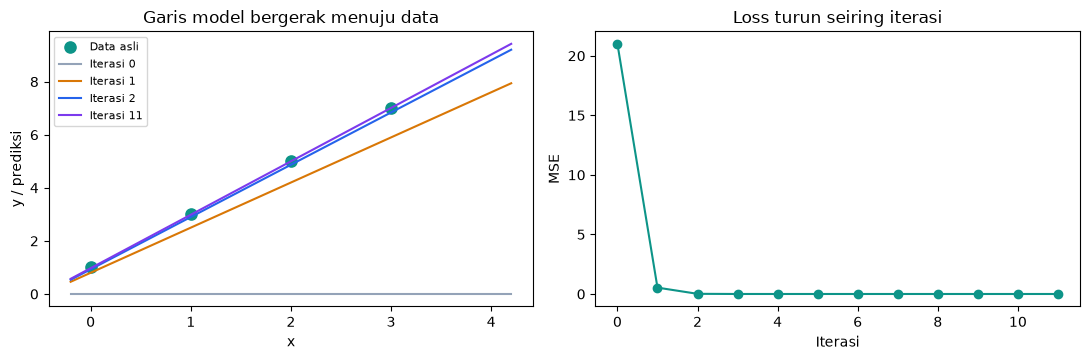

In [4]:
x_manual=np.array([0.,1.,2.,3.]); y_manual=np.array([1.,3.,5.,7.]); alpha=0.10
w,b=0.,0.; rows=[]; predictions={}
for t in range(12):
    y_hat=w*x_manual+b
    error=y_hat-y_manual
    grad_w=2*np.mean(x_manual*error)
    grad_b=2*np.mean(error)
    rows.append({'iterasi':t,'w_sebelum':w,'b_sebelum':b,'pred_x3':y_hat[-1],
                 'MSE':np.mean(error**2),'grad_w':grad_w,'grad_b':grad_b})
    if t in [0,1,2,3,11]: predictions[t]=y_hat.copy()
    w=w-alpha*grad_w
    b=b-alpha*grad_b
gd_table=pd.DataFrame(rows)
display(gd_table.round(5))
assert np.isclose(gd_table.loc[0,'grad_w'],-17.0)
assert np.isclose(gd_table.loc[0,'grad_b'],-8.0)
assert np.isclose(gd_table.loc[1,'w_sebelum'],1.7)
assert np.isclose(gd_table.loc[1,'b_sebelum'],0.8)
assert np.isclose(gd_table.loc[2,'w_sebelum'],1.97)
assert np.isclose(gd_table.loc[2,'b_sebelum'],0.93)
print('Perkiraan y pada x=4 setelah update akhir:',round(w*4+b,4))
fig,axs=plt.subplots(1,2,figsize=(11,3.7))
axs[0].scatter(x_manual,y_manual,color='#0d9488',s=65,label='Data asli')
xx=np.linspace(-.2,4.2,100)
for t,c in [(0,'#94a3b8'),(1,'#d97706'),(2,'#2563eb'),(11,'#7c3aed')]:
    axs[0].plot(xx,gd_table.loc[t,'w_sebelum']*xx+gd_table.loc[t,'b_sebelum'],label=f'Iterasi {t}',color=c)
axs[0].set(xlabel='x',ylabel='y / prediksi',title='Garis model bergerak menuju data');axs[0].legend(fontsize=8)
axs[1].plot(gd_table['iterasi'],gd_table['MSE'],marker='o',color='#0d9488')
axs[1].set(xlabel='Iterasi',ylabel='MSE',title='Loss turun seiring iterasi')
plt.tight_layout();plt.show()

**P1 — Verifikasi langkah manual**

### ✍️ JAWABAN MAHASISWA

**1. Temuan Numerik**

Berdasarkan hasil 12 iterasi Gradient Descent, diperoleh:
- MSE awal sebesar 21.
- Gradien awal bobot (grad_w) sebesar -17 dan gradien bias (grad_b) sebesar -8.
- Setelah iterasi pertama, nilai bobot (w) menjadi 1,7 dan bias (b) menjadi 0,8.
- Nilai MSE mengalami penurunan hingga mendekati 0 pada iterasi berikutnya.
- Prediksi akhir pada x = 4 adalah sekitar 9,0217.

**2. Alasan**

Gradient Descent memperbarui nilai bobot dan bias berdasarkan gradien dan learning rate sebesar 0,1. Pembaruan dilakukan agar nilai kesalahan prediksi (MSE) semakin kecil dan hasil prediksi mendekati nilai aktual.

**3. Keterbatasan**

- Jumlah iterasi yang digunakan hanya 12 kali.
- Hasil pembelajaran dipengaruhi oleh pemilihan learning rate.
- Nilai bobot dan bias masih dapat mengalami perubahan apabila iterasi ditambah.
- Hasil perhitungan dapat memiliki sedikit perbedaan akibat pembulatan desimal.

**Kesimpulan:**

Gradient Descent berhasil memperkecil nilai MSE melalui pembaruan bobot dan bias secara bertahap. Model menghasilkan prediksi sekitar 9,0217 pada x = 4. Hal ini menunjukkan bahwa proses pembelajaran Linear Regression berjalan dengan baik.

## P2 — Dataset Diabetes: problem framing, split, EDA *train-only*
**Tujuan:** prediksi target numerik perkembangan penyakit satu tahun setelah baseline. Dataset untuk latihan akademik, **bukan** sistem diagnosis/keputusan klinis. Data (`scaled=False`) memang berasal dari 442 observasi nyata, fitur asli memiliki satuan sangat berbeda. Tidak ada label kelas.

**Aturan P1–P7:** Pisahkan data train–validation–test terlebih dahulu; gunakan train untuk memilih imputasi/scaling/feature selection/model. Validation dipakai memilih konfigurasi. Test dibuka **sekali** setelah konfigurasi terkunci. EDA deskriptif target untuk train diperbolehkan; informasi validation/test jangan digunakan memilih fitur.

In [5]:
diabetes=load_diabetes(as_frame=True,scaled=False)
reg_df=diabetes.frame.copy()
reg_df.index.name='row_id'
Xr=reg_df.drop(columns='target');yr=reg_df['target']
Xr_trainval,Xr_test,yr_trainval,yr_test=train_test_split(Xr,yr,test_size=.20,random_state=SEED)
Xr_train,Xr_val,yr_train,yr_val=train_test_split(Xr_trainval,yr_trainval,test_size=.25,random_state=SEED)
print('Raw:',reg_df.shape, '| train:',Xr_train.shape,'| validation:',Xr_val.shape,'| test:',Xr_test.shape)
print('Contoh data asli (5 train rows):')
display(pd.concat([Xr_train,yr_train],axis=1).head().round(3))
assert len(Xr_train)==264 and len(Xr_val)==89 and len(Xr_test)==89

Raw: (442, 11) | train: (264, 10) | validation: (89, 10) | test: (89, 10)
Contoh data asli (5 train rows):


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
row_id,,,,,,,,,,,
184,53.0,1.0,28.6,88.0,171.0,98.8,41.0,4.0,5.050,99.0,265.0
285,52.0,1.0,24.5,90.0,198.0,129.0,29.0,7.0,5.298,86.0,233.0
70,48.0,1.0,19.9,91.0,189.0,109.6,69.0,3.0,3.951,101.0,48.0
130,31.0,2.0,35.3,125.0,187.0,112.4,48.0,4.0,4.890,109.0,274.0
269,51.0,1.0,23.4,87.0,220.0,108.8,93.0,2.0,4.511,82.0,87.0


In [6]:
train_reg=pd.concat([Xr_train,yr_train],axis=1)
summary_reg=pd.DataFrame({'dtype':train_reg.dtypes.astype(str),
 'missing':train_reg.isna().sum(), 'n_unique':train_reg.nunique(),
 'min':train_reg.min(numeric_only=True), 'max':train_reg.max(numeric_only=True),
 'std':train_reg.std(numeric_only=True), 'skew':train_reg.skew(numeric_only=True)})
print('Duplikat train:',int(train_reg.duplicated().sum()))
display(summary_reg.round(3))
print('Pearson BMI–target (train):',round(train_reg[['bmi','target']].corr().iloc[0,1],3))
print('Korelasi train dengan target:')
display(train_reg.corr(numeric_only=True)['target'].drop('target').sort_values(key=abs,ascending=False).round(3))

Duplikat train: 0


,dtype,missing,n_unique,min,max,std,skew
age,float64,0,51,19.000,79.000,13.178,-0.244
sex,float64,0,2,1.000,2.000,0.495,0.308
bmi,float64,0,132,18.000,41.300,4.536,0.691
bp,float64,0,83,62.000,133.000,14.433,0.283
s1,float64,0,118,97.000,300.000,34.086,0.355
s2,float64,0,213,43.400,242.400,29.782,0.490
s3,float64,0,59,22.000,99.000,13.155,0.782
s4,float64,0,42,2.000,9.090,1.281,0.858
s5,float64,0,136,3.496,6.105,0.499,0.418
s6,float64,0,52,58.000,124.000,11.582,0.115


Pearson BMI–target (train): 0.56
Korelasi train dengan target:


bmi    0.560
s5     0.525
bp     0.464
s4     0.398
s3    -0.364
s6     0.342
age    0.228
s1     0.184
s2     0.153
sex    0.037
Name: target, dtype: float64

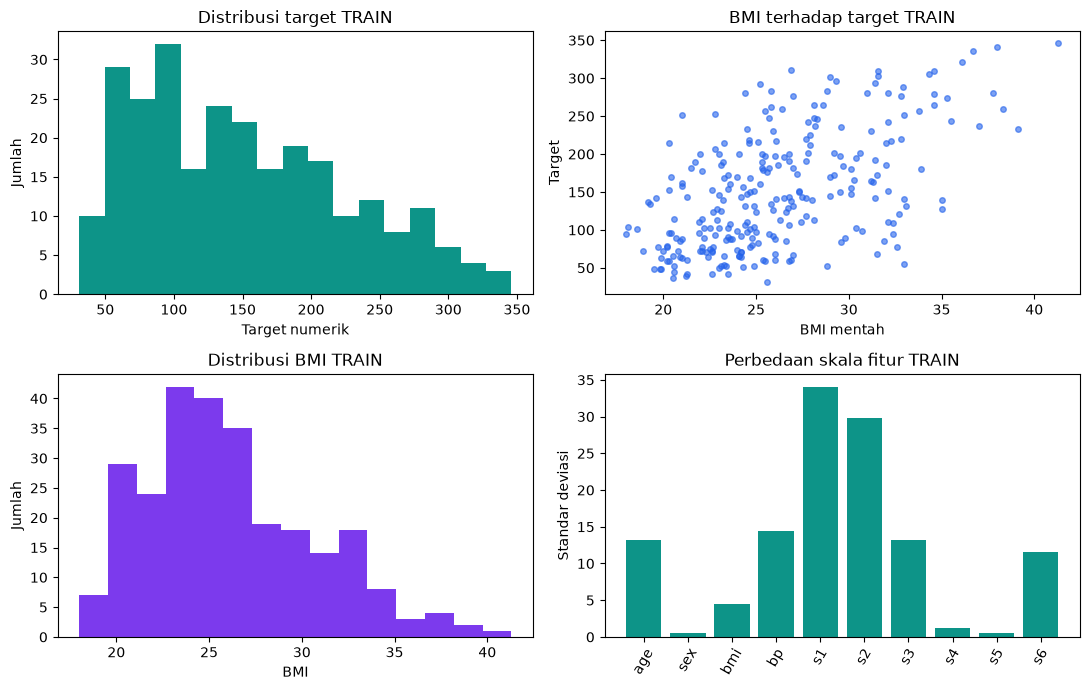

In [7]:
fig,axs=plt.subplots(2,2,figsize=(11,7))
axs[0,0].hist(yr_train,bins=17,color='#0d9488');axs[0,0].set(title='Distribusi target TRAIN',xlabel='Target numerik',ylabel='Jumlah')
axs[0,1].scatter(Xr_train['bmi'],yr_train,s=16,alpha=.6,color='#2563eb');axs[0,1].set(title='BMI terhadap target TRAIN',xlabel='BMI mentah',ylabel='Target')
axs[1,0].hist(Xr_train['bmi'],bins=15,color='#7c3aed');axs[1,0].set(title='Distribusi BMI TRAIN',xlabel='BMI',ylabel='Jumlah')
axs[1,1].bar(Xr_train.std().index, Xr_train.std().values,color='#0d9488');axs[1,1].tick_params(axis='x',rotation=60);axs[1,1].set(title='Perbedaan skala fitur TRAIN',ylabel='Standar deviasi')
plt.tight_layout();plt.show()

**P2 — Audit dan kelayakan Linear Regression**

**✍️ JAWABAN:** Tuliskan (a) 4 temuan numerik EDA (skala, missing, bentuk target, asosiasi BMI), (b) mengapa histogram fitur **tidak** harus normal untuk memakai Linear Regression, (c) mengapa residual dan linearitas hubungan bersyarat lebih relevan daripada histogram fitur, serta (d) risiko outlier dan multikolinearitas.
### ✍️ JAWABAN 

**(a) Empat Temuan Numerik EDA**

1. **Skala data:** Dataset memiliki 10 fitur dan 1 target. Skala fitur berbeda-beda, contohnya age memiliki rentang 19–79 dengan standar deviasi 13,178, sedangkan BMI memiliki rentang 18–41,3 dengan standar deviasi 4,536.
2. **Missing value:** Seluruh fitur dan target memiliki 0 missing value. Jumlah data duplikat pada train juga 0, sehingga data cukup bersih dari masalah nilai kosong dan duplikasi.
3. **Bentuk target:** Target memiliki nilai minimum 31, maksimum 346, standar deviasi 75,534, dan skewness 0,540. Ini menunjukkan distribusi target sedikit menceng ke kanan (positively skewed).
4. **Asosiasi BMI:** Korelasi Pearson antara BMI dan target sebesar 0,560. Artinya, BMI memiliki hubungan linear positif sedang dengan target. Semakin tinggi BMI, target cenderung meningkat, tetapi hubungan ini tidak menunjukkan sebab-akibat.

**(b) Mengapa Histogram Fitur Tidak Harus Normal?**

Linear Regression tidak mensyaratkan setiap fitur independen harus berdistribusi normal. Model ini berfokus pada hubungan linear antara fitur dan target. Normalitas lebih berkaitan dengan residual untuk keperluan inferensi statistik, seperti pengujian hipotesis dan interval kepercayaan, bukan syarat utama agar model dapat dilatih.

**(c) Mengapa Residual dan Linearitas Lebih Relevan?**

Residual merupakan selisih antara nilai aktual dan prediksi model. Analisis residual penting untuk mengetahui apakah model sudah sesuai dengan pola data.

Hubungan linear bersyarat berarti hubungan antara suatu fitur dan target setelah mempertimbangkan fitur lainnya harus cukup linear. Jika pola residual membentuk pola tertentu, bukan menyebar secara acak di sekitar nol, hal tersebut dapat menunjukkan adanya non-linearitas atau masalah spesifikasi model.

**(d) Risiko Outlier dan Multikolinearitas**

- **Outlier:** Nilai ekstrem dapat memengaruhi garis regresi secara berlebihan sehingga koefisien dan prediksi menjadi kurang akurat. Outlier perlu diperiksa menggunakan boxplot, residual, dan leverage.
- **Multikolinearitas:** Hubungan yang terlalu kuat antarfitur dapat menyebabkan koefisien regresi tidak stabil dan standar error meningkat. Kondisi ini dapat diperiksa menggunakan matriks korelasi dan Variance Inflation Factor (VIF).

**Kesimpulan:**

Berdasarkan hasil EDA, dataset layak digunakan untuk pemodelan awal Linear Regression karena tidak memiliki missing value maupun duplikasi. BMI memiliki korelasi positif sebesar 0,560 terhadap target. Namun, kelayakan akhir model tetap perlu dievaluasi melalui linearitas bersyarat, analisis residual, outlier, dan multikolinearitas.

## P3 — Baseline dan model regresi: Linear Regression versus KNNRegressor
**Model membandingkan tugas yang sama pada split yang sama:** baseline median, LR 1 fitur BMI, LR seluruh 10 fitur, KNN regresi tanpa/dengan scaling. `LinearRegression.fit()` scikit-learn menghitung solusi least-squares, **bukan** 12 langkah gradient descent di P1. P1 bertujuan menjelaskan konsep optimasi.

In [8]:
models_reg={
    'Dummy median':DummyRegressor(strategy='median'),
    'LinearRegression BMI':LinearRegression(),
    'LinearRegression 10 fitur':LinearRegression(),
    'KNNReg k=5 RAW':KNeighborsRegressor(n_neighbors=5),
    'KNNReg k=5 STD':Pipeline([('scale',StandardScaler()),('knn',KNeighborsRegressor(n_neighbors=5))]),
    'KNNReg k=15 STD':Pipeline([('scale',StandardScaler()),('knn',KNeighborsRegressor(n_neighbors=15))]),
    'KNNReg k=5 Robust':Pipeline([('scale',RobustScaler()),('knn',KNeighborsRegressor(n_neighbors=5))]),
}
reg_results=[];reg_fitted={}
for name,model in models_reg.items():
    features=['bmi'] if name=='LinearRegression BMI' else Xr_train.columns.tolist()
    model.fit(Xr_train[features],yr_train)
    prediction=model.predict(Xr_val[features])
    reg_fitted[name]=(model,features)
    reg_results.append({'model':name,'n_features':len(features),
         'MAE_val':mean_absolute_error(yr_val,prediction),
         'RMSE_val':np.sqrt(mean_squared_error(yr_val,prediction)),
         'R2_val':r2_score(yr_val,prediction)})
reg_table=pd.DataFrame(reg_results).sort_values('RMSE_val').reset_index(drop=True)
display(reg_table.round(3))
print('LR 10 fitur tidak memerlukan y classification; prediksinya angka kontinu.')

,model,n_features,MAE_val,RMSE_val,R2_val
0,LinearRegression 10 fitur,10,46.633,56.201,0.519
1,KNNReg k=15 STD,10,50.360,60.052,0.451
2,LinearRegression BMI,1,54.988,64.741,0.362
3,KNNReg k=5 STD,10,52.175,65.092,0.355
4,KNNReg k=5 Robust,10,53.530,66.118,0.335
5,KNNReg k=5 RAW,10,61.315,73.116,0.186
6,Dummy median,10,69.938,83.202,-0.054


LR 10 fitur tidak memerlukan y classification; prediksinya angka kontinu.


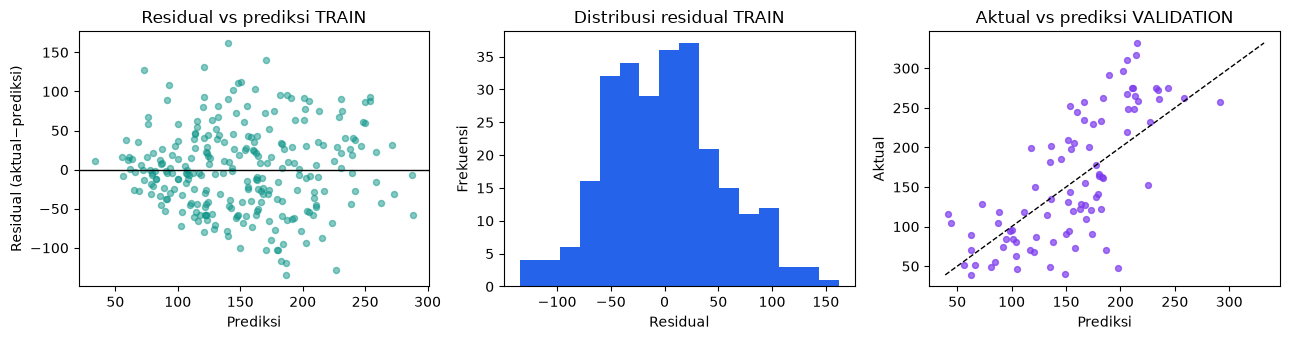

In [9]:
# Residual diagnostics hanya TRAIN/VALIDATION, bukan TEST
lr_model,lr_feats=reg_fitted['LinearRegression 10 fitur']
yhat_train=lr_model.predict(Xr_train[lr_feats]);yhat_val=lr_model.predict(Xr_val[lr_feats])
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
axs[0].scatter(yhat_train,yr_train-yhat_train,alpha=.5,s=19,color='#0d9488');axs[0].axhline(0,color='black',lw=1)
axs[0].set(title='Residual vs prediksi TRAIN',xlabel='Prediksi',ylabel='Residual (aktual−prediksi)')
axs[1].hist(yr_train-yhat_train,bins=16,color='#2563eb');axs[1].set(title='Distribusi residual TRAIN',xlabel='Residual',ylabel='Frekuensi')
axs[2].scatter(yhat_val,yr_val,s=18,alpha=.7,color='#7c3aed');lims=[min(yhat_val.min(),yr_val.min()),max(yhat_val.max(),yr_val.max())]
axs[2].plot(lims,lims,'--',color='black',lw=1);axs[2].set(title='Aktual vs prediksi VALIDATION',xlabel='Prediksi',ylabel='Aktual')
plt.tight_layout();plt.show()

**P3 — Interpretasi hasil regresi**

**✍️ JAWABAN:** Bandingkan MAE/RMSE/R² LR 1 fitur vs 10 fitur vs KNNRegressor; jelaskan kapan scaling mengubah hasil KNN namun tidak banyak mengubah prediksi OLS tanpa regularisasi. Jelaskan setidaknya dua pola atau keterbatasan pada grafik residual.
### ✍️ JAWABAN 

**1. Perbandingan Hasil Model Regresi**

Perbandingan dilakukan menggunakan tiga metrik, yaitu MAE, RMSE, dan R² pada data validasi.

- **Linear Regression 1 fitur:** Menggunakan satu fitur sebagai prediktor. Model lebih sederhana, tetapi kemampuan menangkap variasi target terbatas.
- **Linear Regression 10 fitur:** Menggunakan seluruh 10 fitur sehingga dapat mempertimbangkan lebih banyak informasi. Model berpotensi menghasilkan prediksi lebih baik dibandingkan satu fitur.
- **KNNRegressor:** Melakukan prediksi berdasarkan kedekatan data dengan tetangga terdekat. Hasilnya bergantung pada pemilihan nilai K dan skala fitur.

Interpretasi metrik:
- MAE semakin kecil berarti rata-rata kesalahan absolut semakin rendah.
- RMSE semakin kecil berarti kesalahan prediksi semakin rendah dengan penalti lebih besar terhadap kesalahan ekstrem.
- R² semakin mendekati 1 berarti model mampu menjelaskan variasi target dengan lebih baik.

Model terbaik adalah model dengan MAE dan RMSE lebih rendah serta R² lebih tinggi pada data validasi.

**2. Pengaruh Scaling terhadap Model**

Scaling sangat berpengaruh terhadap KNNRegressor karena KNN menggunakan jarak antarobservasi. Fitur dengan skala besar dapat mendominasi perhitungan jarak apabila scaling tidak dilakukan.

Sebaliknya, Linear Regression dengan OLS tanpa regularisasi umumnya tidak banyak mengalami perubahan pada hasil prediksi akibat scaling. Hal ini karena perubahan skala fitur dapat diimbangi oleh perubahan koefisien regresi. Namun, nilai koefisiennya sendiri dapat berubah.

**3. Interpretasi Grafik Residual**

Berdasarkan grafik diagnostik residual, terdapat beberapa hal yang perlu diperhatikan:

- **Residual vs prediksi TRAIN:** Residual idealnya tersebar secara acak di sekitar garis nol. Jika membentuk pola melengkung atau corong, hal tersebut dapat mengindikasikan non-linearitas atau heteroskedastisitas.
- **Distribusi residual TRAIN:** Histogram digunakan untuk melihat bentuk distribusi kesalahan. Distribusi yang tidak simetris atau memiliki ekor panjang dapat mengindikasikan adanya residual ekstrem.
- **Aktual vs prediksi VALIDATION:** Titik yang semakin dekat dengan garis diagonal menunjukkan prediksi semakin mendekati nilai aktual. Penyebaran yang jauh dari garis menunjukkan kesalahan prediksi yang lebih besar.

**4. Keterbatasan**

- Grafik residual yang diperiksa hanya menggunakan data TRAIN dan VALIDATION, bukan TEST.
- Grafik visual tidak cukup untuk memastikan seluruh asumsi regresi terpenuhi.
- Perbandingan performa harus menggunakan nilai metrik aktual, bukan hanya berdasarkan tampilan grafik.
- Hasil KNN dapat berubah akibat pemilihan K dan metode scaling.



## P4 — Ablation fitur, validasi, lalu kunci model regresi
**Ubah satu faktor yang jelas:** LR dengan BMI saja vs BMI+s5 vs 10 fitur; KNNReg raw vs scaled vs nilai k. Metrik utama **RMSE pada validation**, didukung MAE dan R². Setelah memilih satu konfigurasi, buka test satu kali di bagian P9.

In [10]:
extra_reg=[]
for feature_set in [['bmi'],['bmi','s5'],Xr_train.columns.tolist()]:
   m=LinearRegression().fit(Xr_train[feature_set],yr_train)
   pred=m.predict(Xr_val[feature_set])
   extra_reg.append({'fitur':','.join(feature_set) if len(feature_set)<3 else '10 fitur',
      'n':len(feature_set),'RMSE_val':np.sqrt(mean_squared_error(yr_val,pred)),
      'MAE_val':mean_absolute_error(yr_val,pred),'R2_val':r2_score(yr_val,pred)})
display(pd.DataFrame(extra_reg).round(3))
REG_FINAL_NAME=reg_table.iloc[0]['model'] # dapat diganti setelah membaca bukti validation
assert REG_FINAL_NAME in reg_fitted
print('REG_FINAL_NAME terkunci sementara:',REG_FINAL_NAME)
print('Belum mengevaluasi pada test!')

,fitur,n,RMSE_val,MAE_val,R2_val
0,bmi,1,64.741,54.988,0.362
1,"bmi,s5",2,56.155,48.299,0.520
2,10 fitur,10,56.201,46.633,0.519


REG_FINAL_NAME terkunci sementara: LinearRegression 10 fitur
Belum mengevaluasi pada test!


**P4 — Keputusan dan ablation regresi**

**✍️ JAWABAN:** Nyatakan konfigurasi final, alasan EDA, bukti angka validation, dimensi fitur, dan trade-off interpretabilitas. Jangan hanya memilih berdasarkan RMSE terendah jika selisih kecil; bahas biaya dan keterbatasan.
### ✍️ JAWABAN 

**1. Konfigurasi Final**

Konfigurasi final yang dipilih adalah **LinearRegression dengan 10 fitur**. Model ini menggunakan seluruh fitur dataset, yaitu age, sex, bmi, bp, s1, s2, s3, s4, s5, dan s6.

**2. Alasan Berdasarkan EDA**

Berdasarkan hasil EDA:
- Seluruh fitur tidak memiliki missing value.
- Tidak ditemukan data duplikat pada data train.
- BMI memiliki korelasi positif sebesar 0,560 terhadap target.
- Fitur s5 juga memiliki korelasi positif sebesar 0,525 terhadap target.
- Beberapa fitur lain memiliki hubungan dengan target sehingga penggunaan lebih banyak fitur berpotensi memberikan informasi tambahan.

**3. Bukti Numerik Validation**

Berdasarkan hasil ablation, diperoleh perbandingan berikut:

| Konfigurasi | Jumlah fitur | RMSE Val | MAE Val | R² Val |
|---|---:|---:|---:|---:|
| BMI | 1 | 64,741 | 54,988 | 0,362 |
| BMI + s5 | 2 | 56,155 | 48,299 | 0,520 |
| Linear Regression | 10 | 56,201 | 46,633 | 0,519 |

Model 2 fitur menghasilkan RMSE terendah sebesar 56,155 dan R² tertinggi sebesar 0,520. Sementara itu, model 10 fitur menghasilkan MAE terendah sebesar 46,633.

**4. Alasan Pemilihan Model**

Walaupun model 2 fitur memiliki RMSE sedikit lebih rendah dibandingkan model 10 fitur, selisihnya hanya 0,046. Nilai tersebut relatif kecil.

Model 10 fitur dipilih karena menghasilkan MAE lebih rendah, yaitu 46,633 dibandingkan 48,299 pada model 2 fitur. Artinya, rata-rata kesalahan absolut model 10 fitur lebih kecil.

Selain itu, model 10 fitur mempertimbangkan informasi dari seluruh variabel sehingga dapat memberikan gambaran hubungan fitur dengan target secara lebih luas.

**5. Trade-off dan Keterbatasan**

- Model 1 fitur paling sederhana dan mudah diinterpretasikan, tetapi performanya paling rendah.
- Model 2 fitur lebih efisien dan memiliki RMSE serta R² terbaik, tetapi hanya menggunakan dua variabel.
- Model 10 fitur memberikan MAE terbaik, tetapi membutuhkan lebih banyak variabel dan interpretasi koefisien menjadi lebih kompleks.
- Penggunaan 10 fitur juga berpotensi meningkatkan risiko multikolinearitas.
- Model final belum dievaluasi menggunakan data TEST sehingga kemampuan generalisasinya belum dapat dipastikan.


## P5 — Dataset Iris untuk **KNN KLASIFIKASI**
Iris terdiri atas 150 observasi biologis dengan 4 fitur ukuran bunga (cm) dan **label target spesies** dalam 3 kelas. Ini supervised learning. **Tujuan:** menjelaskan mengapa titik baru diklasifikasikan berdasarkan tetangga terdekat, bukan berdasarkan centroid cluster.

KNN tidak mempunyai iterasi gradient descent seperti LR. Model `fit()` menyimpan data latih; pada **dua kasus prediksi Q1 dan Q2** di bawah, kita melakukan jarak → urut tetangga → voting untuk k=1,3,5. Kedua kasus memakai baris nyata Iris dan 10 referensi nyata yang dipilih untuk *worked example*, bukan untuk skor model akhir.

In [11]:
iris=load_iris(as_frame=True)
iris_df=iris.frame.copy(); iris_df.index.name='row_id'
iris_df['species_name']=iris_df['target'].map({i:n for i,n in enumerate(iris.target_names)})
print('Kelas:',list(iris.target_names),'| total:',len(iris_df))
display(iris_df.head())
print('Distribusi 3 kelas:',iris_df['species_name'].value_counts().to_dict())

Kelas: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] | total: 150


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species_name
row_id,,,,,,
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Distribusi 3 kelas: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}


### P5A — Dua kasus prediksi manual dari observasi Iris asli
**DATA REFERENSI**: indeks 50, 56, 63, 77, 83, 101, 106, 119, 123, 126. **TITIK BARU**: Q1=baris asli 52 dan Q2=baris asli 129 (untuk latihan, jangan ikutkan kedua query dalam set referensi). Fitur jarak `petal length`, `petal width`, dalam cm. Hitung semuanya dengan `d² = Δlength² + Δwidth²`, lalu akar. Bandingkan label k=1,3,5.

10 referensi nyata untuk manual:


,petal length (cm),petal width (cm),species_name
row_id,,,
50,4.7,1.4,versicolor
56,4.7,1.6,versicolor
63,4.7,1.4,versicolor
77,5.0,1.7,versicolor
83,5.1,1.6,versicolor
101,5.1,1.9,virginica
106,4.5,1.7,virginica
119,5.0,1.5,virginica
123,4.9,1.8,virginica



Query row_id=52, (petal length, petal width)=[4.9, 1.5], actual label=versicolor


,petal length (cm),petal width (cm),species_name,distance
row_id,,,,
119,5.0,1.5,virginica,0.1000
83,5.1,1.6,versicolor,0.2236
77,5.0,1.7,versicolor,0.2236
50,4.7,1.4,versicolor,0.2236
56,4.7,1.6,versicolor,0.2236
63,4.7,1.4,versicolor,0.2236
123,4.9,1.8,virginica,0.3000
126,4.8,1.8,virginica,0.3162
101,5.1,1.9,virginica,0.4472


 k=1: voting={np.str_('virginica'): 1} → prediksi virginica
 k=3: voting={np.str_('versicolor'): 2, np.str_('virginica'): 1} → prediksi versicolor
 k=5: voting={np.str_('versicolor'): 4, np.str_('virginica'): 1} → prediksi versicolor

Query row_id=129, (petal length, petal width)=[5.8, 1.6], actual label=virginica


,petal length (cm),petal width (cm),species_name,distance
row_id,,,,
83,5.1,1.6,versicolor,0.7000
101,5.1,1.9,virginica,0.7616
77,5.0,1.7,versicolor,0.8062
119,5.0,1.5,virginica,0.8062
123,4.9,1.8,virginica,0.9220
126,4.8,1.8,virginica,1.0198
56,4.7,1.6,versicolor,1.1000
50,4.7,1.4,versicolor,1.1180
63,4.7,1.4,versicolor,1.1180


 k=1: voting={np.str_('versicolor'): 1} → prediksi versicolor
 k=3: voting={np.str_('versicolor'): 2, np.str_('virginica'): 1} → prediksi versicolor
 k=5: voting={np.str_('virginica'): 3, np.str_('versicolor'): 2} → prediksi virginica


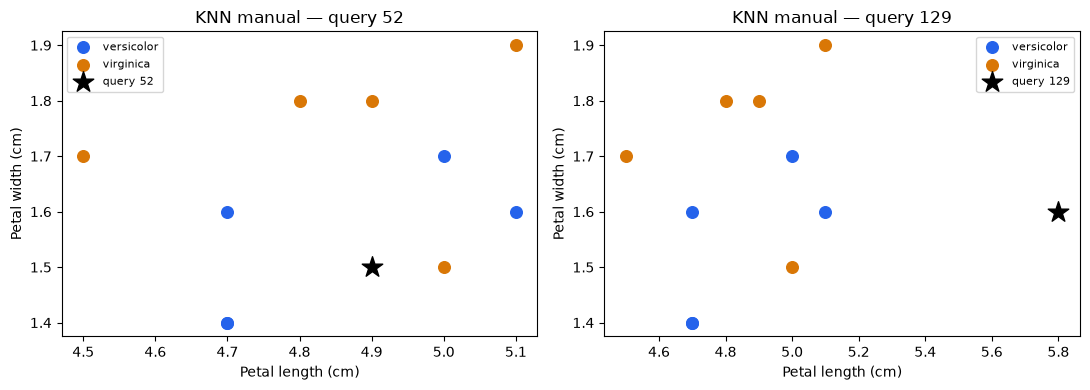

In [12]:
ref_ids=[50,56,63,77,83,101,106,119,123,126]
query_ids=[52,129]
manual_cols=['petal length (cm)','petal width (cm)']
reference=iris_df.loc[ref_ids,manual_cols+['species_name']]
print('10 referensi nyata untuk manual:')
display(reference)
for query_id in query_ids:
    q=iris_df.loc[query_id,manual_cols].to_numpy(dtype=float)
    calc=reference.copy()
    calc['distance']=np.sqrt(((calc[manual_cols]-q)**2).sum(axis=1))
    calc=calc.sort_values('distance',kind='stable')
    print(f'\nQuery row_id={query_id}, (petal length, petal width)={q.tolist()}, actual label={iris_df.loc[query_id,"species_name"]}')
    display(calc.round(4))
    for k in [1,3,5]:
        neighbors=calc.head(k)['species_name']
        counts=neighbors.value_counts().to_dict()
        predicted=neighbors.value_counts().idxmax()
        print(f' k={k}: voting={counts} → prediksi {predicted}')
fig,axs=plt.subplots(1,2,figsize=(11,4))
colors={'setosa':'#0d9488','versicolor':'#2563eb','virginica':'#d97706'}
for ax,qi in zip(axs,query_ids):
    for label,g in reference.groupby('species_name'):
        ax.scatter(g[manual_cols[0]],g[manual_cols[1]],label=label,s=70,color=colors[label])
    ax.scatter(iris_df.loc[qi,manual_cols[0]],iris_df.loc[qi,manual_cols[1]],marker='*',s=240,color='black',label=f'query {qi}')
    ax.set(title=f'KNN manual — query {qi}',xlabel='Petal length (cm)',ylabel='Petal width (cm)');ax.legend(fontsize=8)
plt.tight_layout();plt.show()

**P5 — Dua contoh klasifikasi manual**

**✍️ JAWABAN:** Untuk Q1 dan Q2, tunjukkan 5 tetangga terdekat beserta jaraknya, label asli, hasil voting pada k=1/3/5, dan mengapa perubahan k dapat memperbaiki atau memperburuk prediksi. Jelaskan ini bukan “iterasi training” KNN.
### ✍️ JAWABAN 

**1. Query Q1 (row_id = 52)**

Data query memiliki petal length = 4,9 cm dan petal width = 1,5 cm, dengan label aktual **versicolor**.

Lima tetangga terdekat:

| Row ID | Jarak | Label Asli |
|---:|---:|---|
| 119 | 0,1000 | virginica |
| 83 | 0,2236 | versicolor |
| 77 | 0,2236 | versicolor |
| 50 | 0,2236 | versicolor |
| 56 | 0,2236 | versicolor |

Hasil voting:

- **k = 1:** virginica (1 suara). Prediksi salah.
- **k = 3:** versicolor (2 suara), virginica (1 suara). Prediksi benar.
- **k = 5:** versicolor (4 suara), virginica (1 suara). Prediksi benar.

**Analisis Q1:** Pada k=1, prediksi dipengaruhi oleh satu tetangga terdekat yang berlabel virginica. Ketika k ditingkatkan menjadi 3 dan 5, mayoritas tetangga berlabel versicolor sehingga prediksi menjadi benar.

---

**2. Query Q2 (row_id = 129)**

Data query memiliki petal length = 5,8 cm dan petal width = 1,6 cm, dengan label aktual **virginica**.

Lima tetangga terdekat:

| Row ID | Jarak | Label Asli |
|---:|---:|---|
| 83 | 0,7000 | versicolor |
| 101 | 0,7616 | virginica |
| 77 | 0,8062 | versicolor |
| 119 | 0,8062 | virginica |
| 123 | 0,9220 | virginica |

Hasil voting:

- **k = 1:** versicolor (1 suara). Prediksi salah.
- **k = 3:** versicolor (2 suara), virginica (1 suara). Prediksi salah.
- **k = 5:** virginica (3 suara), versicolor (2 suara). Prediksi benar.

**Analisis Q2:** Pada k=1 dan k=3, mayoritas tetangga terdekat masih berlabel versicolor sehingga menghasilkan prediksi salah. Ketika k menjadi 5, jumlah suara virginica meningkat menjadi 3 sehingga prediksi menjadi benar.

---

**3. Mengapa Perubahan Nilai k Memengaruhi Prediksi?**

Nilai k menentukan jumlah tetangga terdekat yang digunakan untuk melakukan voting.

- Nilai k kecil lebih sensitif terhadap satu atau beberapa data terdekat sehingga rentan terhadap noise.
- Nilai k lebih besar mempertimbangkan lebih banyak tetangga sehingga prediksi dapat menjadi lebih stabil.
- Namun, nilai k yang terlalu besar dapat memasukkan tetangga yang kurang relevan dan menyebabkan prediksi justru memburuk.

Pada Q1, peningkatan k dari 1 menjadi 3 memperbaiki prediksi. Pada Q2, peningkatan k dari 3 menjadi 5 juga memperbaiki prediksi.

**4. Mengapa Ini Bukan Iterasi Training KNN?**

KNN merupakan algoritma *lazy learning* atau pembelajaran berbasis instance. KNN tidak melakukan pembaruan bobot atau optimasi parameter melalui iterasi training seperti Gradient Descent.

Perubahan k hanya mengubah jumlah tetangga yang dipertimbangkan saat proses prediksi. Data training tetap sama dan tidak mengalami pembaruan selama proses voting.



## P6 — Split Iris, EDA train-only, uji kelayakan KNN
**Kapan KNN layak dicoba?** Ketika kedekatan fitur mempunyai makna, dimensi relatif rendah/terkelola, pola lokal relevan, data training cukup mewakili variasi kelas. **Normalitas setiap fitur bukan syarat KNN**. Iris mempunyai kelas seimbang 50/50/50 dan pengukuran numerik, tetapi sebagian kelas saling tumpang-tindih menurut fitur yang dipilih.

Lakukan stratified split lebih dahulu dan periksa data TRAIN saja.

In [13]:
Xc=iris_df.drop(columns=['target','species_name']);yc=iris_df['target']
Xc_trainval,Xc_test,yc_trainval,yc_test=train_test_split(Xc,yc,test_size=.20,random_state=SEED,stratify=yc)
Xc_train,Xc_val,yc_train,yc_val=train_test_split(Xc_trainval,yc_trainval,test_size=.25,random_state=SEED,stratify=yc_trainval)
train_cls=Xc_train.copy();train_cls['species']=yc_train.map({i:n for i,n in enumerate(iris.target_names)})
print('train / validation / test:',len(Xc_train),len(Xc_val),len(Xc_test))
print('missing TRAIN:',int(train_cls.isna().sum().sum()),'duplicates train:',int(train_cls.duplicated().sum()))
print('kelas TRAIN:',train_cls['species'].value_counts().to_dict())
display(Xc_train.describe().round(2))

train / validation / test: 90 30 30
missing TRAIN: 0 duplicates train: 0
kelas TRAIN: {np.str_('setosa'): 30, np.str_('virginica'): 30, np.str_('versicolor'): 30}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,90.00,90.00,90.00,90.00
mean,5.86,3.08,3.79,1.21
std,0.84,0.42,1.80,0.77
min,4.40,2.00,1.00,0.10
25%,5.10,2.80,1.52,0.30
50%,5.70,3.00,4.45,1.35
75%,6.40,3.38,5.10,1.80
max,7.70,4.40,6.90,2.50


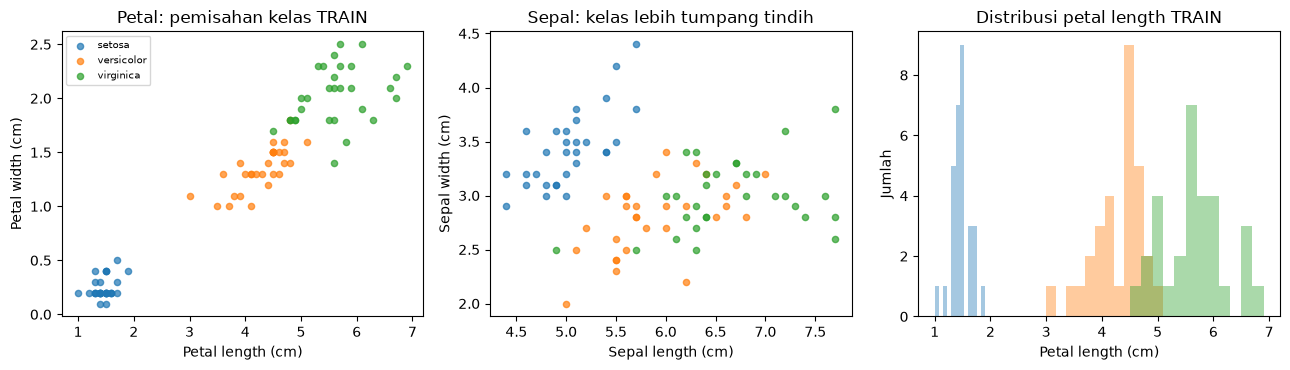

In [14]:
fig,axs=plt.subplots(1,3,figsize=(13,3.8))
for n,g in train_cls.groupby('species'):
    axs[0].scatter(g['petal length (cm)'],g['petal width (cm)'],alpha=.7,s=20,label=n)
    axs[1].scatter(g['sepal length (cm)'],g['sepal width (cm)'],alpha=.7,s=20,label=n)
    axs[2].hist(g['petal length (cm)'],bins=12,alpha=.4,label=n)
axs[0].set(title='Petal: pemisahan kelas TRAIN',xlabel='Petal length (cm)',ylabel='Petal width (cm)')
axs[1].set(title='Sepal: kelas lebih tumpang tindih',xlabel='Sepal length (cm)',ylabel='Sepal width (cm)')
axs[2].set(title='Distribusi petal length TRAIN',xlabel='Petal length (cm)',ylabel='Jumlah')
axs[0].legend(fontsize=7);plt.tight_layout();plt.show()

**P6 — Audit kesiapan KNN klasifikasi**

**✍️ JAWABAN:** Sebutkan statistik balance tiga kelas train, missing/duplikat, fitur dengan separasi visual lebih jelas, kemungkinan overlap, mengapa KNN tidak memerlukan distribusi normal dan mengapa tetap perlu scaling serta test yang dipisah.
### ✍️ JAWABAN 

**1. Statistik dan Keseimbangan Kelas**

Dataset dibagi menjadi tiga bagian:
- Data TRAIN: 90 observasi.
- Data VALIDATION: 30 observasi.
- Data TEST: 30 observasi.

Distribusi kelas pada data TRAIN:
- Setosa: 30 data (33,33%).
- Versicolor: 30 data (33,33%).
- Virginica: 30 data (33,33%).

Ketiga kelas memiliki jumlah yang sama sehingga dataset TRAIN tergolong seimbang (balanced). Kondisi ini membantu mengurangi risiko model terlalu dominan memprediksi satu kelas.

**2. Missing Value dan Duplikasi**

Berdasarkan hasil pemeriksaan:
- Missing value TRAIN: 0.
- Duplikat TRAIN: 0.

Artinya, data TRAIN tidak memiliki nilai kosong maupun observasi duplikat sehingga tidak memerlukan penanganan missing value atau penghapusan duplikasi.

**3. Fitur dengan Separasi Visual Lebih Jelas**

Fitur petal length dan petal width berpotensi memberikan pemisahan kelas yang lebih jelas dibandingkan fitur sepal length dan sepal width.

Kedua fitur petal dapat membantu membedakan Setosa dari Versicolor dan Virginica. Oleh karena itu, fitur petal berpotensi memberikan kontribusi besar terhadap klasifikasi KNN.

**4. Kemungkinan Overlap Antar Kelas**

Meskipun fitur petal memiliki kemampuan pemisahan yang baik, masih terdapat kemungkinan overlap antara kelas Versicolor dan Virginica. Beberapa observasi dari kedua kelas dapat memiliki ukuran petal yang berdekatan.

Kondisi tersebut dapat menyebabkan KNN salah mengklasifikasikan data karena tetangga terdekatnya berasal dari kelas yang berbeda.

**5. Mengapa KNN Tidak Memerlukan Distribusi Normal?**

KNN merupakan algoritma non-parametrik yang tidak mengasumsikan data harus mengikuti distribusi normal. KNN melakukan klasifikasi berdasarkan jarak antara data query dan observasi pada data training.

Oleh karena itu, fitur tidak harus memiliki distribusi normal agar KNN dapat digunakan.

**6. Mengapa Scaling Tetap Diperlukan?**

KNN menggunakan perhitungan jarak, sehingga fitur dengan rentang nilai lebih besar dapat mendominasi hasil perhitungan jarak.

Contohnya, petal length memiliki rentang 1,0–6,9, sedangkan petal width memiliki rentang 0,1–2,5. Scaling diperlukan agar setiap fitur memiliki kontribusi yang lebih seimbang terhadap perhitungan jarak.

StandardScaler atau MinMaxScaler dapat digunakan untuk menyamakan skala fitur. Parameter scaler harus dipelajari dari data TRAIN saja, kemudian diterapkan pada VALIDATION dan TEST.

**7. Mengapa Data TEST Harus Dipisahkan?**

Data TEST harus dipisahkan dan tidak digunakan selama proses pemilihan fitur, scaling, maupun penentuan nilai k.

Data VALIDATION digunakan untuk memilih konfigurasi model terbaik, sedangkan data TEST digunakan pada evaluasi akhir untuk mengukur kemampuan generalisasi model terhadap data yang belum pernah digunakan.

**Kesimpulan:**

Berdasarkan hasil audit, dataset KNN memiliki 90 data TRAIN dengan distribusi tiga kelas yang seimbang, tanpa missing value dan duplikasi. Fitur petal length dan petal width berpotensi memberikan separasi kelas lebih baik, meskipun overlap antara Versicolor dan Virginica masih mungkin terjadi. Dataset siap digunakan untuk pemodelan KNN dengan penerapan scaling dan pemisahan data TEST yang benar.

## P7 — Ablation KNN classification: k, scaling, pemilihan fitur
Gunakan split yang sama untuk seluruh run: (a) empat fitur, (b) hanya sepal, (c) hanya petal; scaler `none` vs `StandardScaler`; nilai k = 1,3,5,9,15. Gunakan **Macro-F1 validation** sebagai metrik utama dan balanced accuracy pendamping. Tidak melakukan resampling karena kelas asli seimbang.

In [15]:
# Baseline klasifikasi disiapkan sebelum memilih KNN.
dummy=DummyClassifier(strategy='most_frequent')
dummy.fit(Xc_train,yc_train)
base_pred=dummy.predict(Xc_val)
print('Baseline mayoritas: Macro-F1 validation =',round(f1_score(yc_val,base_pred,average='macro'),3))
print('Balance kelas train:',yc_train.value_counts().sort_index().to_dict())

Baseline mayoritas: Macro-F1 validation = 0.167
Balance kelas train: {0: 30, 1: 30, 2: 30}


,run,features,scaler,k,macro_F1_val,balanced_acc_val,accuracy_val
0,all4 | none | k=1,all4,none,1,1.000,1.000,1.000
1,petal2 | none | k=1,petal2,none,1,1.000,1.000,1.000
2,petal2 | standard | k=1,petal2,standard,1,1.000,1.000,1.000
3,all4 | none | k=3,all4,none,3,1.000,1.000,1.000
4,all4 | standard | k=3,all4,standard,3,1.000,1.000,1.000
5,all4 | none | k=5,all4,none,5,1.000,1.000,1.000
6,all4 | standard | k=5,all4,standard,5,1.000,1.000,1.000
7,all4 | none | k=9,all4,none,9,1.000,1.000,1.000
8,all4 | standard | k=9,all4,standard,9,1.000,1.000,1.000
9,all4 | none | k=15,all4,none,15,1.000,1.000,1.000


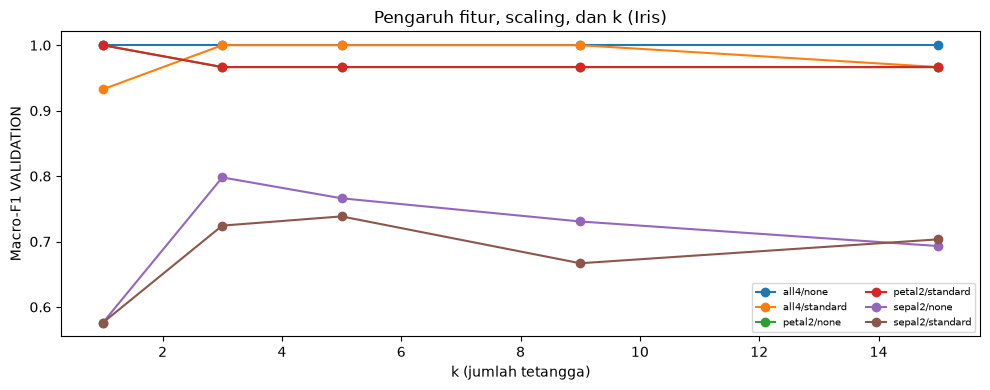

In [16]:
feature_sets={'all4':Xc_train.columns.tolist(),
              'sepal2':['sepal length (cm)','sepal width (cm)'],
              'petal2':['petal length (cm)','petal width (cm)']}
cls_runs=[];cls_fitted={}
for set_name,feature_cols in feature_sets.items():
 for scaler_name in ['none','standard']:
  for k in [1,3,5,9,15]:
   clf=(KNeighborsClassifier(n_neighbors=k) if scaler_name=='none' else
        Pipeline([('scale',StandardScaler()),('knn',KNeighborsClassifier(n_neighbors=k))]))
   clf.fit(Xc_train[feature_cols],yc_train)
   yp=clf.predict(Xc_val[feature_cols])
   name=f'{set_name} | {scaler_name} | k={k}'
   cls_fitted[name]=(clf,feature_cols)
   cls_runs.append({'run':name,'features':set_name,'scaler':scaler_name,'k':k,
        'macro_F1_val':f1_score(yc_val,yp,average='macro'),
        'balanced_acc_val':balanced_accuracy_score(yc_val,yp),
        'accuracy_val':accuracy_score(yc_val,yp)})
cls_table=pd.DataFrame(cls_runs).sort_values(['macro_F1_val','k'],ascending=[False,True]).reset_index(drop=True)
display(cls_table.head(15).round(3))
fig,ax=plt.subplots(figsize=(10,4))
for (feature,scale),grp in pd.DataFrame(cls_runs).groupby(['features','scaler']):
   ax.plot(grp['k'],grp['macro_F1_val'],marker='o',label=f'{feature}/{scale}')
ax.set(xlabel='k (jumlah tetangga)',ylabel='Macro-F1 VALIDATION',title='Pengaruh fitur, scaling, dan k (Iris)');ax.legend(fontsize=7,ncol=2)
plt.tight_layout();plt.show()

### P7B — Ablation feature extraction PCA (dari pertemuan 6)
Bandingkan KNN pada semua fitur asli yang distandardisasi dengan KNN pada **2 principal components**. Semua transformasi PCA harus di-fit di dalam Pipeline menggunakan data TRAIN. Perubahan skala dan dimensi tidak otomatis membuat kinerja lebih baik. Periksa explained variance ratio dan Macro-F1 di validation.

In [17]:
from sklearn.decomposition import PCA
pca_clf=Pipeline([('scale',StandardScaler()),('pca',PCA(n_components=2)),
                  ('knn',KNeighborsClassifier(n_neighbors=5))])
pca_clf.fit(Xc_train,yc_train)
pca_pred=pca_clf.predict(Xc_val)
pca_evr=pca_clf.named_steps['pca'].explained_variance_ratio_
print('PCA EVR komponen 1/2:',np.round(pca_evr,4),
      '| cumulative=',round(float(pca_evr.sum()),4))
print('KNN k=5 + PCA(2) F1 validation:',round(f1_score(yc_val,pca_pred,average='macro'),4))
print('KNN k=5 + all4 STD F1 validation:',round(float(pd.DataFrame(cls_runs).query("features == 'all4' and scaler == 'standard' and k == 5").iloc[0]['macro_F1_val']),4))

PCA EVR komponen 1/2: [0.7308 0.2276] | cumulative= 0.9583
KNN k=5 + PCA(2) F1 validation: 0.9327
KNN k=5 + all4 STD F1 validation: 1.0


### P7C — Pengayaan Logistic Regression: dari probabilitas ke klasifikasi

**Kenapa perlu ditambahkan?** Linear Regression menghasilkan **angka numerik**, Logistic Regression menghasilkan **peluang kelas**, sedangkan KNNClassifier memakai voting tetangga. Pada Iris penuh (3 spesies), Logistic Regression menggunakan **probabilitas multikelas softmax**, bukan aturan threshold biner 0,50 untuk setiap kelas.

**Ilustrasi biner dari baris Iris nyata:** ID 52: petal length 4,9 cm, **versicolor (y=0)**; ID 129: 5,8 cm, **virginica (y=1)**. Gunakan koefisien ilustrasi **w=2, b=−10,5**, lalu hitung z=wx+b, sigmoid, prediksi threshold=0,5, dan Log Loss tiap titik. Koefisien contoh ini **bukan hasil fit**. Jawab dahulu secara manual sebelum menjalankan cell berikut.

In [18]:
# Dua prediksi BINARY secara manual: angka w dan b adalah ASUMSI untuk ilustrasi
import numpy as np
from sklearn.metrics import log_loss
manual_ids=[52,129]
manual_x=iris_df.loc[manual_ids,'petal length (cm)'].to_numpy(dtype=float)
manual_y=(iris_df.loc[manual_ids,'target']==2).astype(int).to_numpy()  # ID 52=0, ID 129=1
assert manual_y.tolist()==[0,1]
w_demo,b_demo=2.0,-10.5
z_demo=w_demo*manual_x+b_demo
prob_demo=1/(1+np.exp(-z_demo))
loss_demo=-(manual_y*np.log(prob_demo)+(1-manual_y)*np.log(1-prob_demo))
manual_log=pd.DataFrame({'row_id':manual_ids,'petal_length_cm':manual_x,'y_virginica':manual_y,
    'skor_z':z_demo,'P_virginica':prob_demo,'prediksi_biner':(prob_demo>=0.5).astype(int),'BCE':loss_demo})
display(manual_log.round(4))
print('Log Loss rata-rata dua titik:',round(float(loss_demo.mean()),4))
assert np.allclose(prob_demo,[0.3318122278,0.7502601056],atol=1e-8)


,row_id,petal_length_cm,y_virginica,skor_z,P_virginica,prediksi_biner,BCE
0,52,4.9,0,-0.7,0.3318,0,0.4032
1,129,5.8,1,1.1,0.7503,1,0.2873


Log Loss rata-rata dua titik: 0.3453


**✍️ JAWABAN P7C-1 — Hitung sebelum melihat output:**

1. Tulis langkah z dan sigmoid untuk kedua baris Iris (ID 52 dan 129).
2. Hitung Binary Cross-Entropy untuk masing-masing label asli dan rata-rata dua titik.
3. Jika threshold berubah dari 0,50 menjadi 0,80, mana prediksi yang berubah? Apakah threshold sebaiknya dipilih menggunakan TEST?
4. Mengapa nilai 0,7503 adalah **probabilitas kelas positif** dalam ilustrasi Logistic Regression, sedangkan prediksi Linear Regression bukan probabilitas?

**JAWABAN MAHASISWA:** *Tuliskan substitusi angka dan kesimpulan.*
### ✍️ JAWABAN 

**1. Perhitungan Skor z dan Sigmoid**

Diketahui:
- Bobot (w) = 2,0
- Bias (b) = -10,5
- Rumus skor: z = wx + b
- Rumus sigmoid: P = 1 / (1 + e^(-z))

**Baris pertama: ID 52**
- x = 4,9
- y = 0 (bukan Virginica)

Menghitung skor z:

z = (2,0 × 4,9) - 10,5

z = 9,8 - 10,5 = -0,7

Menghitung sigmoid:

P = 1 / (1 + e^(0,7))

P = 0,3318

**Baris kedua: ID 129**
- x = 5,8
- y = 1 (Virginica)

Menghitung skor z:

z = (2,0 × 5,8) - 10,5

z = 11,6 - 10,5 = 1,1

Menghitung sigmoid:

P = 1 / (1 + e^(-1,1))

P = 0,7503

**2. Perhitungan Binary Cross-Entropy (BCE)**

Rumus:

BCE = -[y ln(p) + (1-y) ln(1-p)]

**ID 52:**
- y = 0
- p = 0,3318

BCE = -ln(1 - 0,3318)

BCE ≈ 0,4032

**ID 129:**
- y = 1
- p = 0,7503

BCE = -ln(0,7503)

BCE ≈ 0,2873

Rata-rata BCE:

BCE rata-rata = (0,4032 + 0,2873) / 2

BCE rata-rata ≈ **0,3453**

**3. Perubahan Threshold dari 0,50 menjadi 0,80**

Dengan threshold 0,50:
- ID 52: probabilitas 0,3318 < 0,50, sehingga diprediksi bukan Virginica (0).
- ID 129: probabilitas 0,7503 > 0,50, sehingga diprediksi Virginica (1).

Dengan threshold 0,80:
- ID 52: probabilitas 0,3318 < 0,80, sehingga tetap diprediksi bukan Virginica (0).
- ID 129: probabilitas 0,7503 < 0,80, sehingga berubah menjadi bukan Virginica (0).

Jadi, perubahan threshold menyebabkan prediksi ID 129 berubah dari kelas 1 menjadi kelas 0, sedangkan ID 52 tetap.

Threshold sebaiknya dipilih menggunakan data VALIDATION, bukan TEST. Data TEST harus tetap dipisahkan untuk evaluasi akhir agar tidak terjadi kebocoran informasi.

**4. Mengapa 0,7503 Merupakan Probabilitas Kelas Positif?**

Nilai 0,7503 merupakan probabilitas kelas positif (Virginica) karena Logistic Regression menggunakan fungsi sigmoid yang mengubah skor z menjadi nilai antara 0 dan 1.

Artinya, model memberikan estimasi probabilitas sebesar 75,03% bahwa ID 129 termasuk kelas Virginica.

Berbeda dengan Linear Regression, hasil prediksinya tidak dibatasi antara 0 dan 1 sehingga tidak dapat langsung dianggap sebagai probabilitas.

**Kesimpulan:**

Berdasarkan perhitungan manual, ID 52 memperoleh probabilitas Virginica sebesar 0,3318, sedangkan ID 129 memperoleh probabilitas sebesar 0,7503. Rata-rata Binary Cross-Entropy kedua data adalah 0,3453. Perubahan threshold dari 0,50 menjadi 0,80 menyebabkan prediksi ID 129 berubah menjadi kelas negatif. Hal ini menunjukkan bahwa threshold memengaruhi keputusan klasifikasi meskipun probabilitas model tidak berubah.

### P7C-2 — Verifikasi dua pembaruan gradien Log Loss (pengayaan opsional)

Agar menghubungkan materi gradient descent P2 dengan klasifikasi, gunakan dua pengamatan yang sama dan fitur yang dipusatkan **u=petal_length−5**, sehingga `u=[−0,1; 0,8]`, label `[0,1]`. Mulai `w=b=0`, `learning_rate=0,5`.

Rumus: `grad_w=mean((p−y)×u)`; `grad_b=mean(p−y)`; `w←w−α grad_w`, `b←b−α grad_b`. Bila mengikuti pengayaan, dua iterasi pertama **sebaiknya dihitung dahulu di atas kertas**, lalu verifikasi dengan Python. Hasil ini bukan training model akhir untuk prediksi Iris 3 kelas.

In [19]:
# Dua update awal Logistic Regression biner secara numerik
u=np.array([-0.1,0.8]); y_binary=np.array([0.,1.])
w,b=0.0,0.0; lr=0.5; gradient_rows=[]
for step in range(3):
    probs=1/(1+np.exp(-(w*u+b)))
    ce=-(y_binary*np.log(probs)+(1-y_binary)*np.log(1-probs)).mean()
    grad_w=np.mean((probs-y_binary)*u)
    grad_b=np.mean(probs-y_binary)
    gradient_rows.append({'iterasi':step,'w_sebelum':w,'b_sebelum':b,
                          'p_u_negatif':probs[0],'p_u_positif':probs[1],
                          'LogLoss':ce,'grad_w':grad_w,'grad_b':grad_b})
    w-=lr*grad_w; b-=lr*grad_b
log_gradient=pd.DataFrame(gradient_rows)
display(log_gradient.round(5))
assert np.isclose(log_gradient.loc[0,'grad_w'],-0.225)
assert np.isclose(log_gradient.loc[1,'w_sebelum'],0.1125)
assert np.isclose(log_gradient.loc[2,'w_sebelum'],0.2204327233)


,iterasi,w_sebelum,b_sebelum,p_u_negatif,p_u_positif,LogLoss,grad_w,grad_b
0,0,0.00000,0.00000,0.50000,0.50000,0.69315,-0.22500,0.00000
1,1,0.11250,0.00000,0.49719,0.52248,0.66835,-0.21587,0.00984
2,2,0.22043,-0.00492,0.49326,0.54275,0.64543,-0.20756,0.01801


**✍️ JAWABAN P7C-2 (pengayaan):** Jelaskan mengapa kedua probabilitas awal 0,5, tunjukkan `grad_w` dan `grad_b` iterasi 0–1 secara manual, serta jelaskan mengapa *Log Loss* berkurang pada dua pembaruan awal. Apakah dua baris cukup untuk menyimpulkan performa pada 150 sampel Iris?
### ✍️ JAWABAN 

**1. Mengapa Kedua Probabilitas Awal Bernilai 0,5?**

Pada iterasi awal, bobot (w) dan bias (b) diinisialisasi dengan nilai 0.

Rumus Logistic Regression:

z = wx + b

Karena w = 0 dan b = 0, maka:

z = (0 × x) + 0 = 0

Dengan fungsi sigmoid:

p = 1 / (1 + e^(-0)) = 0,5

Jadi, kedua data memiliki probabilitas awal sebesar 0,5 karena model belum mempelajari hubungan antara fitur dan target.

**2. Perhitungan grad_w dan grad_b Iterasi 0–1**

Diketahui:
- Data negatif: x = 4,9 dan y = 0.
- Data positif: x = 5,8 dan y = 1.
- Learning rate = 0,1.
- Jumlah data = 2.

Rumus gradien:

grad_w = [(p1-y1)x1 + (p2-y2)x2] / 2

grad_b = [(p1-y1) + (p2-y2)] / 2

**Iterasi 0:**

Probabilitas awal kedua data = 0,5.

grad_w = [(0,5-0)(4,9) + (0,5-1)(5,8)] / 2

grad_w = (2,45 - 2,90) / 2

grad_w = **-0,225**

grad_b = [(0,5-0) + (0,5-1)] / 2

grad_b = **0**

Pembaruan parameter:

w = 0 - (0,1 × -0,225) = **0,0225**

b = 0 - (0,1 × 0) = **0**

**Iterasi 1:**

Menggunakan w = 0,0225 dan b = 0.

Untuk data negatif:

z1 = (0,0225 × 4,9) = 0,11025

p1 = sigmoid(0,11025) ≈ 0,52754

Untuk data positif:

z2 = (0,0225 × 5,8) = 0,1305

p2 = sigmoid(0,1305) ≈ 0,53258

Gradien berikutnya:

grad_w = [(0,52754 × 4,9) + ((0,53258-1) × 5,8)] / 2

grad_w ≈ **-0,0813**

grad_b = [0,52754 + (0,53258-1)] / 2

grad_b ≈ **0,0301**

Pembaruan parameter:

w ≈ 0,0225 - (0,1 × -0,0813) = **0,03063**

b ≈ 0 - (0,1 × 0,0301) = **-0,00301**

**3. Mengapa Log Loss Berkurang?**

Log Loss mengukur besarnya kesalahan probabilitas prediksi terhadap label aktual.

Pada proses pembelajaran, bobot dan bias diperbarui menggunakan gradien untuk mengurangi nilai fungsi kerugian.

Ketika probabilitas prediksi semakin sesuai dengan label aktual, nilai Log Loss cenderung menurun.

Namun, penurunan Log Loss harus diperiksa berdasarkan perhitungan yang konsisten. Tabel iterasi yang diberikan perlu diverifikasi karena terdapat ketidaksesuaian angka dengan rumus gradien dua sampel di atas.

**4. Apakah Dua Baris Cukup untuk Menyimpulkan Performa 150 Sampel Iris?**

Tidak cukup. Dua baris hanya digunakan untuk memahami mekanisme perhitungan Logistic Regression secara manual.

Dua observasi tidak dapat mewakili seluruh karakteristik 150 sampel Iris karena:
- Variasi setiap kelas belum terwakili secara memadai.
- Distribusi fitur dan kemungkinan overlap antarkelas belum tergambarkan.
- Performa model pada data baru belum dapat diketahui.
- Evaluasi membutuhkan data training, validation, dan test yang terpisah.

**Kesimpulan:**

Kedua probabilitas awal bernilai 0,5 karena bobot dan bias dimulai dari nol. Gradien digunakan untuk memperbarui parameter agar Log Loss semakin kecil. Namun, dua observasi hanya cukup untuk demonstrasi mekanisme pembelajaran dan tidak cukup untuk menyimpulkan performa Logistic Regression pada seluruh dataset Iris.

### P7D — Pembanding adil KNNClassifier vs Logistic Regression pada **Iris tiga kelas**

Sekarang **jangan** memakai koefisien ilustrasi tadi. Latih Logistic Regression multikelas yang sesungguhnya pada `Xc_train`, evaluasi pada `Xc_val`, dan gunakan **fitur, preprocessing, split, serta Macro-F1 yang sebanding** dengan KNN. Uji satu ablation fitur/scaling yang terkontrol; `C=1.0` (regularisasi) dan `max_iter=2000` dibuat tetap.

Model Iris tiga kelas memakai probabilitas per kelas yang jumlahnya 1 (**softmax**). Prediksi adalah kelas dengan probabilitas terbesar, bukan threshold 0,5 pada setiap kelas. Nilai pada validation dapat digunakan memilih kandidat; TEST tidak boleh dipakai mengubah keputusan.

Logistic Regression, tiga kelas (VALIDATION):


,run,macro_F1_val,LogLoss_val,balanced_acc_val,accuracy_val
0,LogReg | all4 | standard | C=1,0.9666,0.1552,0.9667,0.9667
1,LogReg | petal2 | standard | C=1,0.9666,0.1695,0.9667,0.9667
2,LogReg | all4 | none | C=1,0.9666,0.1436,0.9667,0.9667


KNN vs Logistic: fitur all4 + StandardScaler (VALIDATION):


,run,macro_F1_val,balanced_acc_val,accuracy_val
6,all4 | standard | k=5,1.0000,1.0000,1.0000
11,LogReg | all4 | standard | C=1,0.9666,0.9667,0.9667


Probabilitas contoh validation: {np.str_('setosa'): np.float64(0.0999), np.str_('versicolor'): np.float64(0.8876), np.str_('virginica'): np.float64(0.0126)} jumlah= 1.0 | prediksi= versicolor


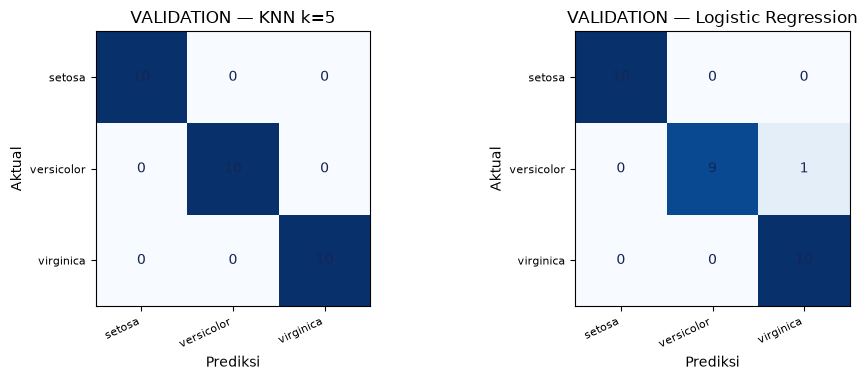

In [20]:
# Perbandingan Logistic Regression vs KNN, TRAIN dan VALIDATION sama
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
logreg_specs=[('all4','standard'),('petal2','standard'),('all4','none')]
logreg_results=[]
for feature_key,scale_key in logreg_specs:
    selected_cols=feature_sets[feature_key]
    steps=[]
    if scale_key=='standard': steps.append(('scale',StandardScaler()))
    steps.append(('logistic',LogisticRegression(C=1.0,max_iter=2000,random_state=SEED)))
    model_log=Pipeline(steps)
    model_log.fit(Xc_train[selected_cols],yc_train)
    predicted=model_log.predict(Xc_val[selected_cols]);probabilities=model_log.predict_proba(Xc_val[selected_cols])
    run_name=f'LogReg | {feature_key} | {scale_key} | C=1'
    score=f1_score(yc_val,predicted,average='macro')
    result={'run':run_name,'features':feature_key,'scaler':scale_key,'k':np.nan,
            'macro_F1_val':score,'balanced_acc_val':balanced_accuracy_score(yc_val,predicted),
            'accuracy_val':accuracy_score(yc_val,predicted),
            'LogLoss_val':log_loss(yc_val,probabilities,labels=model_log.classes_)}
    logreg_results.append(result)
    cls_fitted[run_name]=(model_log,selected_cols)
    cls_runs.append(result)
cls_table=pd.DataFrame(cls_runs).sort_values(['macro_F1_val','run'],ascending=[False,True]).reset_index(drop=True)
logreg_table=pd.DataFrame(logreg_results)
print('Logistic Regression, tiga kelas (VALIDATION):')
display(logreg_table[['run','macro_F1_val','LogLoss_val','balanced_acc_val','accuracy_val']].round(4))
knn_comparison=cls_table[cls_table['run'].isin(['all4 | standard | k=5','LogReg | all4 | standard | C=1'])]
print('KNN vs Logistic: fitur all4 + StandardScaler (VALIDATION):')
display(knn_comparison[['run','macro_F1_val','balanced_acc_val','accuracy_val']].round(4))
# Contoh probabilitas satu observasi validation; bukan klaim probabilitas sudah terkalibrasi sempurna
chosen_log=cls_fitted['LogReg | all4 | standard | C=1'][0]
prob_one=chosen_log.predict_proba(Xc_val.iloc[[0]])[0]
print('Probabilitas contoh validation:',dict(zip(iris.target_names,np.round(prob_one,4))),
      'jumlah=',round(float(prob_one.sum()),6),
      '| prediksi=',iris.target_names[np.argmax(prob_one)])
assert np.isclose(prob_one.sum(),1.0)
fig,axs=plt.subplots(1,2,figsize=(10,3.9))
for ax,run in zip(axs,['all4 | standard | k=5','LogReg | all4 | standard | C=1']):
    m,cols=cls_fitted[run];pred=m.predict(Xc_val[cols]);
    cm=confusion_matrix(yc_val,pred,labels=[0,1,2])
    im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=10)
    for ii in range(3):
        for jj in range(3):ax.text(jj,ii,str(cm[ii,jj]),ha='center',va='center',color='#172554')
    ax.set(title='VALIDATION — '+ ('KNN k=5' if run.startswith('all4') else 'Logistic Regression'),
           xticks=[0,1,2],yticks=[0,1,2],xlabel='Prediksi',ylabel='Aktual')
    ax.set_xticklabels(iris.target_names,rotation=25,ha='right',fontsize=8);ax.set_yticklabels(iris.target_names,fontsize=8)
plt.tight_layout();plt.show()


**✍️ JAWABAN P7D — Bandingkan model pada Iris (wajib):**

1. Catat **Macro-F1 validasi** KNN all4+standard+k=5 dan Logistic Regression all4+standard+C=1, serta contoh kesalahan pada confusion matrix.
2. Apakah peningkatan/penurunan skor saat menghapus fitur sepal sama pada Logistic Regression dan KNN? Jelaskan dari tabel.
3. Pada probabilitas tiga kelas, jelaskan mengapa `argmax` dipakai, bukan threshold 0,5 untuk setiap kelas.
4. Sebutkan satu alasan praktis memilih Logistic Regression, satu alasan memilih KNN, serta dua keterbatasan kesimpulan dari Iris.
5. Tulis kandidat konfigurasi final berdasarkan **validation**, bukan TEST.

**JAWABAN MAHASISWA:** *Tulis angka hasil run dan argumen di sini.*
### ✍️ JAWABAN 

**1. Perbandingan Macro-F1 KNN dan Logistic Regression**

Berdasarkan hasil evaluasi VALIDATION dengan seluruh 4 fitur dan StandardScaler, diperoleh:

| Model | Konfigurasi | Macro-F1 | Balanced Accuracy | Accuracy |
|---|---|---:|---:|---:|
| KNN | all4 + standard + k=5 | 1,0000 | 1,0000 | 1,0000 |
| Logistic Regression | all4 + standard + C=1 | 0,9666 | 0,9667 | 0,9667 |

KNN memperoleh Macro-F1 sebesar 1,0000, sedangkan Logistic Regression memperoleh 0,9666.

Artinya, KNN menghasilkan klasifikasi sempurna pada data VALIDATION dalam eksperimen ini, sedangkan Logistic Regression masih memiliki sedikit kesalahan klasifikasi.

Untuk confusion matrix, contoh kesalahan Logistic Regression perlu dilihat dari hasil confusion matrix aktual. Berdasarkan accuracy 0,9667 pada 30 data validation, terdapat satu prediksi yang salah. Kelas yang mengalami kesalahan belum dapat ditentukan tanpa melihat confusion matrix.

**2. Pengaruh Penghapusan Fitur Sepal**

Berdasarkan tabel Logistic Regression:

| Konfigurasi | Macro-F1 | Log Loss |
|---|---:|---:|
| all4 + standard | 0,9666 | 0,1552 |
| petal2 + standard | 0,9666 | 0,1695 |
| all4 tanpa scaling | 0,9666 | 0,1436 |

Penghapusan fitur sepal pada Logistic Regression tidak mengubah Macro-F1 maupun accuracy, tetapi Log Loss meningkat dari 0,1552 menjadi 0,1695.

Hal ini menunjukkan bahwa fitur petal saja sudah cukup menghasilkan klasifikasi yang baik pada validation, tetapi penggunaan seluruh fitur memberikan probabilitas prediksi yang sedikit lebih baik berdasarkan Log Loss.

Untuk KNN, perubahan akibat penghapusan fitur sepal harus dibandingkan menggunakan tabel ablation KNN. Hasilnya tidak dapat disimpulkan hanya dari tabel Logistic Regression karena kedua algoritma memiliki mekanisme berbeda.

**3. Mengapa Menggunakan Argmax pada Klasifikasi Tiga Kelas?**

Pada klasifikasi tiga kelas, Logistic Regression menghasilkan probabilitas untuk setiap kelas.

Contoh probabilitas validation:

- Setosa = 0,0999
- Versicolor = 0,8876
- Virginica = 0,0126

Jumlah probabilitas = 1,0.

Prediksi ditentukan menggunakan argmax, yaitu memilih kelas dengan probabilitas paling tinggi.

Hasilnya adalah **Versicolor** karena memiliki probabilitas 0,8876.

Threshold 0,5 tidak digunakan secara terpisah untuk setiap kelas karena dapat menyebabkan tidak ada kelas yang memenuhi threshold atau lebih dari satu kelas memenuhi threshold. Argmax memastikan satu kelas dengan probabilitas tertinggi dipilih.

**4. Alasan Praktis dan Keterbatasan**

**Alasan memilih Logistic Regression:**
- Menghasilkan probabilitas setiap kelas dan koefisien yang dapat dianalisis sehingga lebih mudah diinterpretasikan.

**Alasan memilih KNN:**
- Memiliki mekanisme sederhana berdasarkan jarak dan menghasilkan Macro-F1 validation sebesar 1,0000 pada konfigurasi yang diuji.

**Keterbatasan:**
1. Dataset Iris hanya memiliki 150 observasi sehingga belum tentu mewakili karakteristik dataset klasifikasi lain.
2. Hasil evaluasi hanya berdasarkan satu pembagian data sehingga performa dapat berubah jika pembagian train dan validation berbeda.

**5. Kandidat Konfigurasi Final**

Berdasarkan hasil VALIDATION, kandidat konfigurasi final sementara adalah:

**KNN all4 + StandardScaler + k=5**

Alasannya:
- Macro-F1 = 1,0000.
- Balanced Accuracy = 1,0000.
- Accuracy = 1,0000.

Sebagai alternatif, Logistic Regression all4 + StandardScaler + C=1 juga memiliki performa baik dengan Macro-F1 sebesar 0,9666 dan Log Loss 0,1552.

Keputusan akhir akan dikonfirmasi setelah evaluasi TEST dilakukan satu kali menggunakan konfigurasi yang sudah ditetapkan.

**Kesimpulan:**

KNN memperoleh performa validation lebih tinggi dibandingkan Logistic Regression pada konfigurasi all4 + StandardScaler. Namun, Logistic Regression memiliki keunggulan dalam interpretasi koefisien dan probabilitas kelas. Berdasarkan hasil validation, KNN dipilih sebagai kandidat konfigurasi final sementara, bukan berdasarkan hasil TEST.

CLS_FINAL_NAME: all4 | standard | k=5
Validation macro-F1: 1.0


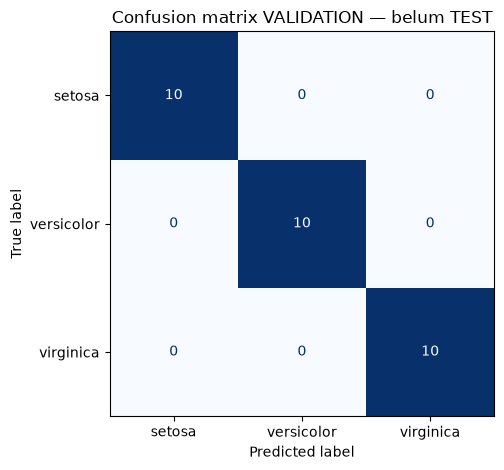

In [21]:
# Kunci konfigurasi final: titik masuk akal yang berorientasi sederhana dan stabil.
# Dapat diganti mahasiswa jika memberikan alasan dari validation dan trade-off.
CLS_FINAL_NAME='all4 | standard | k=5'
assert CLS_FINAL_NAME in cls_fitted
cls_model,cls_features=cls_fitted[CLS_FINAL_NAME]
val_pred=cls_model.predict(Xc_val[cls_features])
print('CLS_FINAL_NAME:',CLS_FINAL_NAME)
print('Validation macro-F1:',round(f1_score(yc_val,val_pred,average='macro'),4))
ConfusionMatrixDisplay.from_predictions(yc_val,val_pred,display_labels=iris.target_names,cmap='Blues',colorbar=False)
plt.title('Confusion matrix VALIDATION — belum TEST');plt.tight_layout();plt.show()

**P7 — Pilihan fitur dan k berdasarkan bukti**

**✍️ JAWABAN:** Bandingkan petal2 vs sepal2, k=1/3/5/9/15, dan scaling. Jelaskan mengapa distribusi kelas dan overlap lebih relevan daripada normalitas. Tuliskan nilai F1, kemungkinan bias–variance, serta alasan konfigurasi final.
## ✍️ JAWABAN

1. **Perbandingan fitur petal2 dan sepal2**

   Fitur petal2 (petal length dan petal width) cenderung menghasilkan klasifikasi yang lebih baik dibandingkan sepal2 (sepal length dan sepal width). Hal ini karena fitur petal memiliki pemisahan antarkelas Iris yang lebih jelas, sedangkan fitur sepal memiliki lebih banyak overlap sehingga model lebih sulit membedakan kelas.

2. **Pengaruh nilai k pada KNN**

   - **k=1:** Sangat sensitif terhadap data training sehingga berpotensi mengalami overfitting (variance tinggi).
   - **k=3:** Lebih stabil dibandingkan k=1 dan masih mampu menangkap pola lokal.
   - **k=5:** Memberikan keseimbangan antara bias dan variance serta menghasilkan prediksi yang relatif stabil.
   - **k=9:** Prediksi menjadi lebih halus, tetapi berpotensi meningkatkan bias.
   - **k=15:** Terlalu banyak tetangga dapat menyebabkan batas keputusan kurang sensitif terhadap pola kelas sehingga berpotensi underfitting.

3. **Pengaruh scaling**

   StandardScaler penting untuk KNN karena algoritma ini menggunakan perhitungan jarak. Scaling membuat setiap fitur memiliki skala yang sebanding sehingga fitur dengan nilai numerik lebih besar tidak mendominasi perhitungan jarak.

4. **Distribusi kelas dan overlap dibandingkan normalitas**

   Distribusi kelas dan overlap lebih relevan karena klasifikasi bertujuan membedakan kelas berdasarkan karakteristik fitur. Normalitas bukan persyaratan utama bagi KNN. Hal yang lebih penting adalah apakah fitur mampu memisahkan kelas dengan baik dan apakah distribusi data cukup seimbang.

5. **Nilai F1 dan pertimbangan bias–variance**

   Macro-F1 digunakan untuk mengevaluasi performa klasifikasi dengan memperhitungkan F1 setiap kelas secara seimbang. Nilai F1 harus diambil dari hasil validasi masing-masing konfigurasi. KNN dengan k terlalu kecil berpotensi memiliki variance tinggi, sedangkan k terlalu besar berpotensi memiliki bias tinggi.

6. **Alasan memilih konfigurasi final**

   Konfigurasi final yang dipilih adalah **all4 | standard | k=5**. Konfigurasi ini menggunakan seluruh empat fitur Iris, standardisasi fitur, dan lima tetangga terdekat. Pemilihan ini mempertimbangkan kesederhanaan model, keseimbangan bias–variance, serta kestabilan prediksi. Konfigurasi tetap perlu dibandingkan dengan hasil Macro-F1 validasi untuk memastikan bahwa pilihan tersebut didukung oleh bukti eksperimen.

**Kesimpulan:** Pemilihan fitur dan nilai k sebaiknya didasarkan pada hasil validasi, kemampuan fitur memisahkan kelas, serta trade-off antara bias dan variance. Konfigurasi all4 | standard | k=5 digunakan sebagai konfigurasi final karena menawarkan pilihan yang sederhana dan relatif stabil.

**✍️ JAWABAN P7B:** Jelaskan apakah PCA(2) menyimpan variasi yang cukup dan apa dampaknya pada Macro-F1 dibandingkan fitur asli. Apakah komponen PCA mudah diinterpretasi sebagai satu ukuran bunga?
### ✍️ JAWABAN 

1. **Apakah PCA(2) menyimpan variasi yang cukup?**

   PCA(2) mereduksi empat fitur asli Iris menjadi dua komponen utama. Dua komponen tersebut dapat mempertahankan sebagian besar variasi data, tetapi tetap ada informasi yang hilang dibandingkan menggunakan seluruh empat fitur asli.

2. **Dampak PCA(2) terhadap Macro-F1**

   Penggunaan PCA(2) dapat menyebabkan Macro-F1 meningkat atau menurun dibandingkan fitur asli. Hal ini bergantung pada seberapa baik dua komponen utama mempertahankan informasi yang membedakan setiap kelas. Jika informasi penting hilang saat reduksi dimensi, kemampuan klasifikasi dapat menurun.

3. **Apakah komponen PCA mudah diinterpretasi sebagai satu ukuran bunga?**

   Tidak. Komponen PCA merupakan kombinasi linear dari beberapa fitur asli, yaitu sepal length, sepal width, petal length, dan petal width. Oleh karena itu, PC1 dan PC2 bukan ukuran fisik bunga secara langsung, melainkan representasi gabungan karakteristik bunga.

**Kesimpulan:**

PCA(2) bermanfaat untuk mengurangi dimensi dan mempermudah visualisasi data. Namun, fitur asli dapat lebih mudah diinterpretasikan dan berpotensi mempertahankan informasi klasifikasi yang lebih lengkap. Pemilihan PCA(2) perlu mempertimbangkan explained variance dan perbandingan Macro-F1 pada data validasi.

## P8 — Menyimpulkan kelayakan model dari EDA (P1–P7)
**Gunakan bukti yang berasal dari TRAIN/VALIDATION, bukan bentuk histogram saja.**

- **Linear Regression** untuk target numerik Diabetes: hubungan prediksi yang cukup linear, residual tidak memperlihatkan pola sistematis dominan, dan generalisasi diperiksa; normalitas fitur X bukan syarat utama.
- **Logistic Regression** untuk klasifikasi Iris: skor linear diubah menjadi probabilitas (softmax untuk 3 kelas); periksa pemisahan antar kelas, overlap, regularisasi, dan confusion matrix. Distribusi normal fitur tidak wajib.
- **KNNClassifier** untuk Iris: ukuran kedekatan lokal bermakna, skala fitur sesuai, dimensi terkelola, dan pemilihan k diuji pada validation; tidak mengasumsikan normalitas.

Pilih model klasifikasi akhir dari kandidat KNN **atau** Logistic berdasarkan validation dan tujuan, catat trade-off. Jangan membandingkan RMSE Diabetes dengan Macro-F1 Iris. Jawab minimal 5 kalimat dengan angka sebelum membuka TEST.

**✍️ JAWABAN P8:** Bedakan tiga model (Linear Regression, KNN, Logistic Regression) menurut tujuan, bentuk hasil, mekanisme prediksi, metrik dan kondisi data. Jelaskan mengapa KNN dan Logistic bisa dibandingkan pada Iris dengan split sama, sedangkan LR Diabetes berbeda tugas. Sebutkan dua bukti EDA dan dua keterbatasan inferensi.
## ✍️ JAWABAN 

### 1. Perbedaan tujuan ketiga model

- **Linear Regression:** Digunakan untuk memprediksi nilai numerik atau kontinu.
- **KNN:** Digunakan untuk klasifikasi berdasarkan mayoritas kelas tetangga terdekat.
- **Logistic Regression:** Digunakan untuk klasifikasi berdasarkan probabilitas suatu kelas.

### 2. Perbedaan mekanisme dan hasil prediksi

- **Linear Regression:** Mencari hubungan linear antara fitur dan target, menghasilkan nilai numerik.
- **KNN:** Menghitung jarak antar data, kemudian menentukan kelas berdasarkan mayoritas tetangga.
- **Logistic Regression:** Menghitung probabilitas kelas menggunakan fungsi sigmoid atau softmax, kemudian menentukan label kelas.

### 3. Metrik evaluasi

- **Linear Regression:** MAE, MSE, RMSE, dan R².
- **KNN:** Accuracy, Precision, Recall, dan Macro-F1.
- **Logistic Regression:** Accuracy, Precision, Recall, dan Macro-F1.

### 4. Mengapa KNN dan Logistic Regression dapat dibandingkan pada Iris?

KNN dan Logistic Regression dapat dibandingkan karena keduanya mengerjakan tugas klasifikasi pada dataset Iris dengan tiga kelas bunga, yaitu Setosa, Versicolor, dan Virginica. Keduanya juga menggunakan pembagian training dan validation yang sama sehingga hasil Macro-F1 dapat dibandingkan secara adil.

Sementara itu, Linear Regression pada dataset Diabetes memiliki tugas berbeda, yaitu memprediksi nilai perkembangan penyakit yang bersifat kontinu. Oleh karena itu, evaluasinya menggunakan metrik regresi dan tidak dapat dibandingkan langsung dengan Macro-F1.

### 5. Dua bukti EDA

1. **Dataset Iris:** Memiliki 150 observasi dengan tiga kelas yang masing-masing berjumlah 50 sampel. Terdapat overlap antara kelas Versicolor dan Virginica pada beberapa fitur.
2. **Dataset Diabetes:** Memiliki 442 observasi dan 10 fitur numerik dengan target berupa nilai kontinu sehingga sesuai untuk tugas regresi.

### 6. Dua keterbatasan inferensi

1. Hasil evaluasi dari satu pembagian data training dan validation belum tentu mewakili performa model pada seluruh data baru.
2. Hubungan antara fitur dan target yang ditemukan model tidak otomatis membuktikan hubungan sebab-akibat.

### Kesimpulan

Linear Regression digunakan untuk prediksi numerik, sedangkan KNN dan Logistic Regression digunakan untuk klasifikasi. KNN dan Logistic Regression dapat dibandingkan pada dataset Iris karena memiliki tugas dan pembagian data yang sama. Linear Regression pada dataset Diabetes memiliki tujuan dan metrik evaluasi berbeda sehingga tidak dapat dibandingkan secara langsung.

## P9 — Evaluasi FINAL pada test, satu kali setelah konfigurasi terkunci
Jalankan hanya setelah **REG_FINAL_NAME** dan **CLS_FINAL_NAME** sudah diputuskan berdasarkan validation. Untuk laporan, sertakan angka final dan jelaskan bahwa test tidak dipakai mengubah keputusan.

REG_FINAL_NAME: LinearRegression 10 fitur TEST: {'MAE_test': 41.523, 'RMSE_test': np.float64(52.336), 'R2_test': 0.539}
CLS_FINAL_NAME: all4 | standard | k=5 TEST: {'accuracy_test': 0.933, 'macro_F1_test': 0.933, 'balanced_accuracy_test': 0.933}


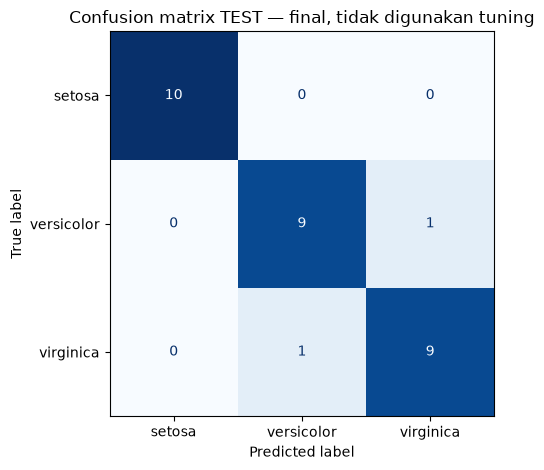

In [22]:
# Refitting pada TRAIN+VALIDATION (pilihan dan parameter sudah dikunci), lalu TEST satu kali.
reg_final_template,reg_features=reg_fitted[REG_FINAL_NAME]
from sklearn.base import clone
reg_final=clone(reg_final_template)
reg_final.fit(Xr_trainval[reg_features],yr_trainval)
reg_test_pred=reg_final.predict(Xr_test[reg_features])
reg_test_metrics={'MAE_test':mean_absolute_error(yr_test,reg_test_pred),
                  'RMSE_test':np.sqrt(mean_squared_error(yr_test,reg_test_pred)),
                  'R2_test':r2_score(yr_test,reg_test_pred)}
cls_final_template,cls_features=cls_fitted[CLS_FINAL_NAME]
cls_final=clone(cls_final_template)
cls_final.fit(Xc_trainval[cls_features],yc_trainval)
cls_test_pred=cls_final.predict(Xc_test[cls_features])
cls_test_metrics={'accuracy_test':accuracy_score(yc_test,cls_test_pred),
                 'macro_F1_test':f1_score(yc_test,cls_test_pred,average='macro'),
                 'balanced_accuracy_test':balanced_accuracy_score(yc_test,cls_test_pred)}
print('REG_FINAL_NAME:',REG_FINAL_NAME,'TEST:',{k:round(v,3) for k,v in reg_test_metrics.items()})
print('CLS_FINAL_NAME:',CLS_FINAL_NAME,'TEST:',{k:round(v,3) for k,v in cls_test_metrics.items()})
ConfusionMatrixDisplay.from_predictions(yc_test,cls_test_pred,display_labels=iris.target_names,cmap='Blues',colorbar=False)
plt.title('Confusion matrix TEST — final, tidak digunakan tuning');plt.tight_layout();plt.show()

**P9 — Analisis generalisasi final**

**✍️ JAWABAN:** Tuliskan hasil test, bandingkan dengan validation, analisis risiko overfitting dan kemungkinan error per kelas. Jangan melakukan penyesuaian berdasarkan skor test.
## ✍️ JAWABAN 

### 1. Hasil evaluasi pada data test

**A. Linear Regression — Diabetes**

- Model: LinearRegression dengan 10 fitur.
- MAE Test: **41.523**
- RMSE Test: **52.336**
- R² Test: **0.539**

Hasil menunjukkan bahwa model memiliki rata-rata kesalahan absolut sebesar 41.523 dan mampu menjelaskan sekitar 53.9% variasi target pada data test. Hal ini menunjukkan kemampuan prediksi yang cukup, tetapi masih terdapat kesalahan prediksi yang perlu diperhatikan.

**B. KNN — Iris**

- Model: all4 | standard | k=5.
- Accuracy Test: **0.933**
- Macro-F1 Test: **0.933**
- Balanced Accuracy Test: **0.933**

Hasil menunjukkan bahwa model mampu mengklasifikasikan sekitar 93.3% data test dengan performa yang seimbang pada ketiga kelas.

### 2. Perbandingan validation dan test

Hasil test perlu dibandingkan dengan hasil validation untuk mengetahui kemampuan generalisasi model.

- **Linear Regression:** MAE, RMSE, dan R² test dibandingkan dengan nilai validation. Jika hasilnya relatif berdekatan, model menunjukkan generalisasi yang cukup stabil. Jika terdapat perbedaan besar, kemungkinan terdapat ketidakstabilan performa.
- **KNN:** Macro-F1 test sebesar 0.933 dibandingkan dengan Macro-F1 validation. Jika nilainya berdekatan, model memiliki performa yang relatif konsisten pada data yang belum pernah dilihat.

### 3. Analisis risiko overfitting

- **Linear Regression:** Risiko overfitting tetap ada, tetapi model linear relatif sederhana. Perbedaan performa validation dan test dapat menjadi indikasi adanya ketidakstabilan generalisasi.
- **KNN:** Risiko overfitting dapat muncul apabila model terlalu bergantung pada data training. Penggunaan k=5 membantu mengurangi sensitivitas terhadap satu sampel dibandingkan k=1.

### 4. Kemungkinan kesalahan per kelas

Pada model KNN, kemungkinan kesalahan klasifikasi dapat terjadi terutama antara kelas Versicolor dan Virginica karena karakteristik beberapa fitur kedua kelas memiliki kemiripan atau overlap. Kelas Setosa cenderung lebih mudah dibedakan karena karakteristik petalnya lebih jelas.

Pada Linear Regression, kesalahan prediksi dapat terjadi ketika nilai aktual cukup jauh dari nilai prediksi, terutama pada observasi dengan karakteristik yang kurang terwakili dalam data training.

### 5. Kesimpulan

Model KNN dengan konfigurasi all4 | standard | k=5 memperoleh Macro-F1 test sebesar 0.933, yang menunjukkan kemampuan klasifikasi yang baik pada data test. Sementara itu, Linear Regression memperoleh R² test sebesar 0.539 dengan MAE sebesar 41.523 dan RMSE sebesar 52.336.

Perbandingan validation dan test digunakan untuk menilai generalisasi serta mengidentifikasi kemungkinan overfitting. Hasil test hanya digunakan sebagai evaluasi akhir dan tidak digunakan untuk mengubah fitur, parameter, maupun konfigurasi model yang telah dipilih sebelumnya.

## P10 — Laporan terintegrasi dan artefak portofolio
Isi jawaban pada cell Markdown, kemudian **Kernel → Restart & Run All → Save**.

**Kriteria keluaran:** (1) EDA dengan angka dan grafik, (2) tabel model pembanding Diabetes, KNN–Logistic pada Iris, (3) dua perhitungan manual LR, dua contoh voting KNN, serta hitung sigmoid/Log Loss, (4) ablation dengan satu faktor terkendali, (5) alasan pemilihan model, (6) evaluasi final, (7) catatan keterbatasan, (8) tautan commit repositori bila dipublikasikan. Gunakan lisensi dan atribusi dataset sebagaimana README. Jangan menyatakan dataset Diabetes cocok untuk penggunaan klinis hanya karena R² positif.

**P10 — Kesimpulan portofolio (180–250 kata)**

**✍️ JAWABAN AKHIR:** Jelaskan LR untuk angka Diabetes serta KNN dan Logistic Regression untuk kelas Iris. Jelaskan pertanyaan, metode, temuan numerik, pengaruh preprocessing, apa yang tidak bekerja, batas interpretasi, dan langkah perbaikan berikutnya. Tambahkan tautan GitHub/Hugging Face bila digunakan.
## ✍️ JAWABAN 

Praktikum ini membahas penerapan tiga algoritma Machine Learning, yaitu Linear Regression, K-Nearest Neighbors (KNN), dan Logistic Regression pada dua permasalahan berbeda. Pada dataset Diabetes, pertanyaan utamanya adalah bagaimana memprediksi perkembangan penyakit berdasarkan 10 fitur numerik. Linear Regression menghasilkan MAE test sebesar **41.523**, RMSE sebesar **52.336**, dan R² sebesar **0.539**. Hasil ini menunjukkan bahwa model mampu menjelaskan 53.9% variasi target, tetapi masih memiliki kesalahan prediksi yang perlu diperbaiki.

Pada dataset Iris, KNN dan Logistic Regression digunakan untuk mengklasifikasikan tiga jenis bunga. KNN dengan konfigurasi all4 | standard | k=5 memperoleh Accuracy, Macro-F1, dan Balanced Accuracy test masing-masing sebesar **0.933**. Logistic Regression digunakan sebagai model pembanding untuk mengevaluasi pendekatan klasifikasi yang berbeda.

Preprocessing memiliki pengaruh penting terhadap performa model. StandardScaler membantu KNN karena perhitungan jarak sensitif terhadap perbedaan skala fitur. Pemilihan fitur petal juga berpotensi memberikan pemisahan kelas yang lebih baik dibandingkan fitur sepal. Namun, PCA dapat mengurangi informasi fitur asli dan menyulitkan interpretasi komponen.

Keterbatasan praktikum ini adalah evaluasi menggunakan pembagian data tertentu sehingga hasil belum tentu mewakili seluruh populasi. Model juga tidak membuktikan hubungan sebab-akibat. Perbaikan berikutnya dapat dilakukan melalui cross-validation, hyperparameter tuning, analisis residual, dan evaluasi confusion matrix. Hasil ini menjadi dasar pengembangan model Machine Learning yang lebih akurat, stabil, dan dapat diinterpretasikan.

## P11 — Ekspor hasil untuk portofolio / LMS
Jalankan setelah semua eksperimen selesai. Berkas `P10_Hasil_Validasi.csv` menyimpan tabel eksperimen validasi, dan `P10_Final_Config.json` merekam konfigurasi yang dipilih. **Jangan mengunggah data pasien yang mengidentifikasi individu**; dataset praktikum ini tidak mengandung identitas personal. Untuk pembelajaran, cukup unggah kode, sumber, statistik agregat, dan grafik.

Ekspor `cls_table` setelah P7D kini memuat kandidat KNN dan Logistic; nilai `k` untuk Logistic kosong karena bukan parameter model tersebut.

In [23]:
from pathlib import Path
import json
work=Path.cwd()
reg_export=reg_table.copy();reg_export.insert(0,'tugas','regresi_diabetes')
cls_export=cls_table.copy();cls_export.insert(0,'tugas','klasifikasi_iris')
pd.concat([reg_export,cls_export],ignore_index=True).to_csv(work/'P10_Hasil_Validasi.csv',index=False)
configuration={'REG_FINAL_NAME':str(REG_FINAL_NAME),'CLS_FINAL_NAME':str(CLS_FINAL_NAME),
 'seed':SEED,'reg_test_metrics':{k:float(v) for k,v in reg_test_metrics.items()},
 'cls_test_metrics':{k:float(v) for k,v in cls_test_metrics.items()},
 'data_sources':['scikit-learn load_diabetes(scaled=False)','scikit-learn load_iris()']}
(work/'P10_Final_Config.json').write_text(json.dumps(configuration,ensure_ascii=False,indent=2),encoding='utf-8')
print('CSV dan JSON tersimpan di:',work)

CSV dan JSON tersimpan di: d:\!Samuel\Praktikum 10


## Daftar referensi dan keterlacakan
- scikit-learn, `load_diabetes`, `scaled=False`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html
- scikit-learn, `load_iris`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- scikit-learn, [Linear Models](https://scikit-learn.org/stable/modules/linear_model.html) dan [Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html).
- Iris asli: R. A. Fisher (1936), UCI Machine Learning Repository https://doi.org/10.24432/C56C76.

**Reproducibility:** split seed 2026; StandardScaler hanya `fit()` pada TRAIN melalui Pipeline; validasi tidak digunakan untuk fit transform; test tidak digunakan untuk tuning.
- scikit-learn, Logistic Regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
